# Approach 3 (combined): SuperSynth ventricles + CSF grown from the cortex

Visualizes `add_csf_combined.py` (TODO.txt, approach 3).

**Ventricles (label 50)**: supersynth approach: SuperSynth ventricles resampled to 0.2 mm, dilated 0.6 mm, pasted only on background.

**CSF (label 24)**: to satisfy *observation 2* (CSF never touches WM / deep GM directly), the CSF is grown only from cortical tissue:
1. cortical mask = cerebral cortex (3) + all labels under `cerebral_cortex` in the tree (hippocampal formation, piriform / olfactory
   cortex) + cerebellar cortex (595/597) + cortical amygdala areas (238, 242)
2. dilated 1 mm (thin CSF layer on the surface)
3. *(optional, default on)* closing of the cortical mask (3 mm): fills the gaps between nearby cortex (wide sulci, cerebrum–cerebellum gap)
   without thickening the outer layer
4. minus the brain mask (tissue + ventricles) → CSF
5. *(optional, default on)* background pockets fully enclosed by brain + CSF become CSF, unless more than 50 % of their boundary is
   WM / deep GM (those stay background, to respect observation 2)
6. *observation 1*: objects (components of brain + CSF) smaller than 30 % of the largest one lose their CSF.

```
cd combined_approach
python add_csf_combined.py --save-intermediates
# options: --no-close-cortex, --close-cortex-mm 4, --no-fill-holes, --max-noncortical-boundary 0.5
```
The last sections compare the three approaches.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy import ndimage as ndi

ROOT = Path.cwd().parent  # add_csf_to_labels/ (shared data/)
IN_DIR = ROOT / "data" / "inputs" / "nxbsimplified" / "labels"
OUT_ROOT = ROOT / "data" / "outputs"
OUT_DIR = OUT_ROOT / "combined_approach"
APPROACHES = ["morphological_approach", "supersynth_approach", "combined_approach"]
summary = json.load(open(OUT_DIR / "summary.json"))
P = summary["params"]
VENT, CSF = P["ventricle_label"], P["csf_label"]
CORTICAL = P["cortical_labels"]
CASES = [c["case"] for c in summary["cases"]]
print({k: v for k, v in P.items() if k != "cortical_labels"})
print("closing / hole filling enabled:", P["close_cortex"], P["fill_holes"])
print(len(CORTICAL), "cortical labels:", CORTICAL)
display(pd.DataFrame(summary["cases"]).set_index("case").round(2))

{'ss_ventricle_labels': [4, 5, 43, 44, 14, 15], 'vent_dilate_mm': 0.6, 'dilate_mm_r': 1.0, 'close_cortex': True, 'close_cortex_mm': 3.0, 'fill_holes': True, 'max_noncortical_boundary': 0.5, 'min_component_frac': 0.3, 'ventricle_label': 50, 'csf_label': 24}
closing / hole filling enabled: True True
60 cortical labels: [3, 99, 100, 125, 157, 238, 242, 326, 339, 340, 341, 342, 343, 344, 345, 346, 347, 364, 365, 367, 368, 369, 370, 371, 372, 373, 374, 375, 404, 405, 407, 408, 409, 410, 411, 418, 419, 420, 421, 422, 432, 558, 559, 561, 562, 563, 564, 565, 566, 567, 568, 569, 571, 572, 573, 574, 575, 576, 595, 597]


,ventricle_cm3,csf_dilation_only_cm3,csf_added_by_closing_cm3,csf_added_by_hole_filling_cm3,holes_rejected_noncortical_cm3,csf_raw_cm3,csf_cm3,csf_removed_small_objects_cm3,noncortical_tissue_touching_csf_cm3,n_components,n_components_kept,seconds
case,,,,,,,,,,,,
case-1,9.19,66.43,1.21,0.00,0.15,67.64,66.96,0.68,0.56,35,1,181.0
case-2,14.68,54.93,0.90,0.00,0.05,55.84,54.68,1.16,0.49,110,1,152.0
case-3,16.12,68.23,2.42,0.00,0.08,70.66,70.42,0.24,0.68,33,1,219.6
case-4,14.87,79.92,3.18,0.11,0.16,83.20,83.15,0.05,1.02,23,1,195.9
case-5,11.87,73.02,1.33,0.00,0.24,74.35,74.05,0.30,0.81,20,1,147.3


In [2]:
COLORS = {
    "cortex": (0.88, 0.40, 0.40),
    "other cortical (hippocampus, olfactory...)": (0.95, 0.60, 0.75),
    "forebrain WM (7)": (0.93, 0.93, 0.93),
    "other tissue": (0.35, 0.58, 0.85),
    f"ventricle ({VENT})": (1.00, 0.82, 0.00),
    f"CSF ({CSF})": (0.20, 0.75, 0.35),
}

def colorize(s):
    rgb = np.zeros(s.shape + (3,))
    rgb[s > 0] = COLORS["other tissue"]
    rgb[np.isin(s, CORTICAL)] = COLORS["other cortical (hippocampus, olfactory...)"]
    rgb[np.isin(s, (3, 595, 597))] = COLORS["cortex"]
    rgb[s == 7] = COLORS["forebrain WM (7)"]
    rgb[s == VENT] = COLORS[f"ventricle ({VENT})"]
    rgb[s == CSF] = COLORS[f"CSF ({CSF})"]
    return rgb

def overlay(s, mask, color, alpha=0.75):
    rgb = np.repeat((0.25 + 0.35 * (s > 0))[..., None], 3, -1)
    rgb[np.isin(s, CORTICAL)] *= 0.75
    rgb[mask] = (1 - alpha) * rgb[mask] + alpha * np.array(color)
    return rgb

def take(vol, axis, idx):
    return np.take(vol, idx, axis=axis).T

VIEW = {0: "sagittal", 1: "coronal", 2: "axial"}

def show(ax, img, title):
    ax.imshow(img, origin="lower", interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")

def legend(fig, items, ncol=None):
    fig.legend(handles=[Patch(color=c, label=k) for k, c in items], loc="lower center",
               ncol=ncol or len(items), frameon=False, fontsize=10)

def load_case(case):
    img = nib.load(IN_DIR / f"{case}.nii.gz")
    d = {"input": np.asarray(img.dataobj), "vox_cm3": float(np.prod(img.header.get_zooms()[:3])) / 1000}
    for a in APPROACHES:
        d[a] = np.asarray(nib.load(OUT_ROOT / a / "labels" / f"{case}.nii.gz").dataobj)
    for f in sorted((OUT_DIR / "intermediates" / case).glob("*.nii.gz")):
        d[f.name.replace(".nii.gz", "")] = np.asarray(nib.load(f).dataobj).astype(bool)
    # non-cortical tissue (WM / deep GM) in direct contact with CSF, per approach
    noncort = (d["input"] > 0) & ~np.isin(d["input"], CORTICAL)
    for a in APPROACHES:
        d[f"contact_{a}"] = ndi.binary_dilation(d[a] == CSF) & noncort
    return d

def ventricle_slices(vent):
    return [int(np.median(i)) for i in np.nonzero(vent)]

def zoom_window(sl, axis, half):
    o = [a for a in range(3) if a != axis]
    win = [slice(max(sl[a] - 2 * half, 0), sl[a] + 2 * half) for a in o]
    return lambda v: take(v, axis, sl[axis])[win[1], win[0]]

In [3]:
def plot_process(case, d):
    sl = ventricle_slices(d["ventricles"])
    steps = [
        ("1. input labels", lambda a, k: colorize(take(d["input"], a, k))),
        ("2. ventricles (SuperSynth)", lambda a, k: overlay(take(d["input"], a, k), take(d["ventricles"], a, k), COLORS[f"ventricle ({VENT})"])),
        ("3. cortical mask", lambda a, k: overlay(take(d["input"], a, k), take(d["cortical_mask"], a, k), (0.6, 0.3, 0.9))),
        (f"4. dilated {P['dilate_mm_r']} mm", lambda a, k: overlay(take(d["input"], a, k), take(d["cortical_dilated"], a, k), (0.9, 0.55, 0.1))),
        (f"5. cortex closed {P['close_cortex_mm']} mm" if P["close_cortex"] else "5. (no closing)",
         lambda a, k: overlay(take(d["input"], a, k), take(d["cortical_closed"], a, k), (0.85, 0.2, 0.6))),
        ("6. minus brain + holes filled", lambda a, k: overlay(take(d["input"], a, k), take(d["csf_raw"], a, k), (0.1, 0.7, 0.8))),
        (f"7. small objects removed (<{P['min_component_frac']:.0%})", lambda a, k: overlay(take(d["input"], a, k), take(d["csf"], a, k), COLORS[f"CSF ({CSF})"])),
        ("8. output labels", lambda a, k: colorize(take(d["combined_approach"], a, k))),
    ]
    fig, axes = plt.subplots(3, len(steps), figsize=(3.3 * len(steps), 3 * 3.5))
    for r, axis in enumerate([0, 1, 2]):
        for c, (title, f) in enumerate(steps):
            show(axes[r, c], f(axis, sl[axis]), title if r == 0 else "")
        axes[r, 0].text(-0.05, 0.5, f"{VIEW[axis]} {sl[axis]}", transform=axes[r, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=11)
    fig.suptitle(f"{case}: process (slices through the ventricle centre)", fontsize=14)
    plt.tight_layout()
    plt.show()

ADDED = {"CSF from the 1 mm dilation": (0.20, 0.75, 0.35), "added by cortex closing": (1.0, 0.0, 1.0),
         "added by hole filling": (0.0, 0.9, 0.9), "pocket rejected (WM / deep GM boundary)": (0.9, 0.0, 0.0)}

def plot_closing(case, d):
    # what the cortex closing and the hole filling add, on the slices where they add the most
    closing = d["csf_raw"] & ~d["csf_dilation_only"] & ~d["holes_filled"]
    extra = closing | d["holes_filled"] | d["holes_rejected"]
    if not extra.any():
        print("closing / hole filling added nothing"); return
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for axis in range(3):
        k = int(np.argmax(extra.sum(axis=tuple(a for a in range(3) if a != axis))))
        img = colorize(take(d["input"], axis, k))
        for m, c in [(d["csf_dilation_only"], "CSF from the 1 mm dilation"), (closing, "added by cortex closing"),
                     (d["holes_filled"], "added by hole filling"), (d["holes_rejected"], "pocket rejected (WM / deep GM boundary)")]:
            img[take(m, axis, k)] = ADDED[c]
        show(axes[axis], img, f"{VIEW[axis]} {k}")
    v = d["vox_cm3"]
    legend(fig, list(ADDED.items()), ncol=4)
    fig.suptitle(f"{case}: closing +{closing.sum() * v:.2f} cm³, hole filling +{d['holes_filled'].sum() * v:.2f} cm³, "
                 f"rejected pockets {d['holes_rejected'].sum() * v:.2f} cm³ (slices where they add the most)", fontsize=13)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

def plot_compare(case, d, half=60):
    """zoom around the ventricle: the three approaches side by side"""
    sl = ventricle_slices(d["ventricles"])
    cols = ["input"] + APPROACHES
    fig, axes = plt.subplots(3, len(cols), figsize=(4.2 * len(cols), 13))
    for r, axis in enumerate([0, 1, 2]):
        crop = zoom_window(sl, axis, half)
        for c, k in enumerate(cols):
            show(axes[r, c], colorize(crop(d[k])), (f"{VIEW[axis]} {sl[axis]}: " if c == 0 else "") + k.replace("_approach", ""))
    legend(fig, list(COLORS.items()), ncol=3)
    fig.suptitle(f"{case}: approaches compared, zoom around the ventricle (±24 mm)", fontsize=13)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

def plot_contact(case, d):
    """observation 2: WM / deep GM voxels touching CSF (red), morphological vs combined"""
    sl = ventricle_slices(d["ventricles"])
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for r, a in enumerate(["morphological_approach", "combined_approach"]):
        for c, axis in enumerate([0, 1, 2]):
            img = colorize(take(d[a], axis, sl[axis]))
            img[take(d[f"contact_{a}"], axis, sl[axis])] = (0.9, 0.0, 0.0)
            show(axes[r, c], img, f"{a.replace('_approach', '')}: {VIEW[axis]} {sl[axis]}")
    vol = {a: d[f"contact_{a}"].sum() * d["vox_cm3"] for a in ["morphological_approach", "combined_approach"]}
    legend(fig, [("WM / deep GM touching CSF", (0.9, 0.0, 0.0))])
    fig.suptitle(f"{case}: CSF in contact with non-cortical tissue: morphological {vol['morphological_approach']:.2f} cm³, "
                 f"combined {vol['combined_approach']:.2f} cm³", fontsize=13)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

def plot_result(case, d, fracs=(0.35, 0.5, 0.65)):
    out = d["combined_approach"]
    idx = np.nonzero(out > 0)
    lo = [i.min() for i in idx]; hi = [i.max() for i in idx]
    fig, axes = plt.subplots(3, 2 * len(fracs), figsize=(3.6 * 2 * len(fracs), 3 * 3.6))
    for r, axis in enumerate([0, 1, 2]):
        for j, f in enumerate(fracs):
            k = int(lo[axis] + f * (hi[axis] - lo[axis]))
            show(axes[r, 2 * j], colorize(take(d["input"], axis, k)), f"{VIEW[axis]} {k}: input")
            show(axes[r, 2 * j + 1], colorize(take(out, axis, k)), f"{VIEW[axis]} {k}: output")
    legend(fig, list(COLORS.items()), ncol=6)
    fig.suptitle(f"{case}: input vs output (combined)", fontsize=14)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

def stats(case, d):
    row = {"case": case}
    for a in APPROACHES:
        n = a.replace("_approach", "")
        row[f"ventricle {n}"] = (d[a] == VENT).sum() * d["vox_cm3"]
        row[f"CSF {n}"] = (d[a] == CSF).sum() * d["vox_cm3"]
        row[f"WM/deepGM touching CSF {n}"] = d[f"contact_{a}"].sum() * d["vox_cm3"]
    return row

## Per-case process and results

For each case: (a) every step on slices through the ventricle centre; (b) what the cortex closing and the hole filling add; (c) the three approaches side by side (zoom); (d) WM / deep GM in contact with CSF (observation 2), morphological vs combined; (e) input vs output at three positions per view.

### case-1

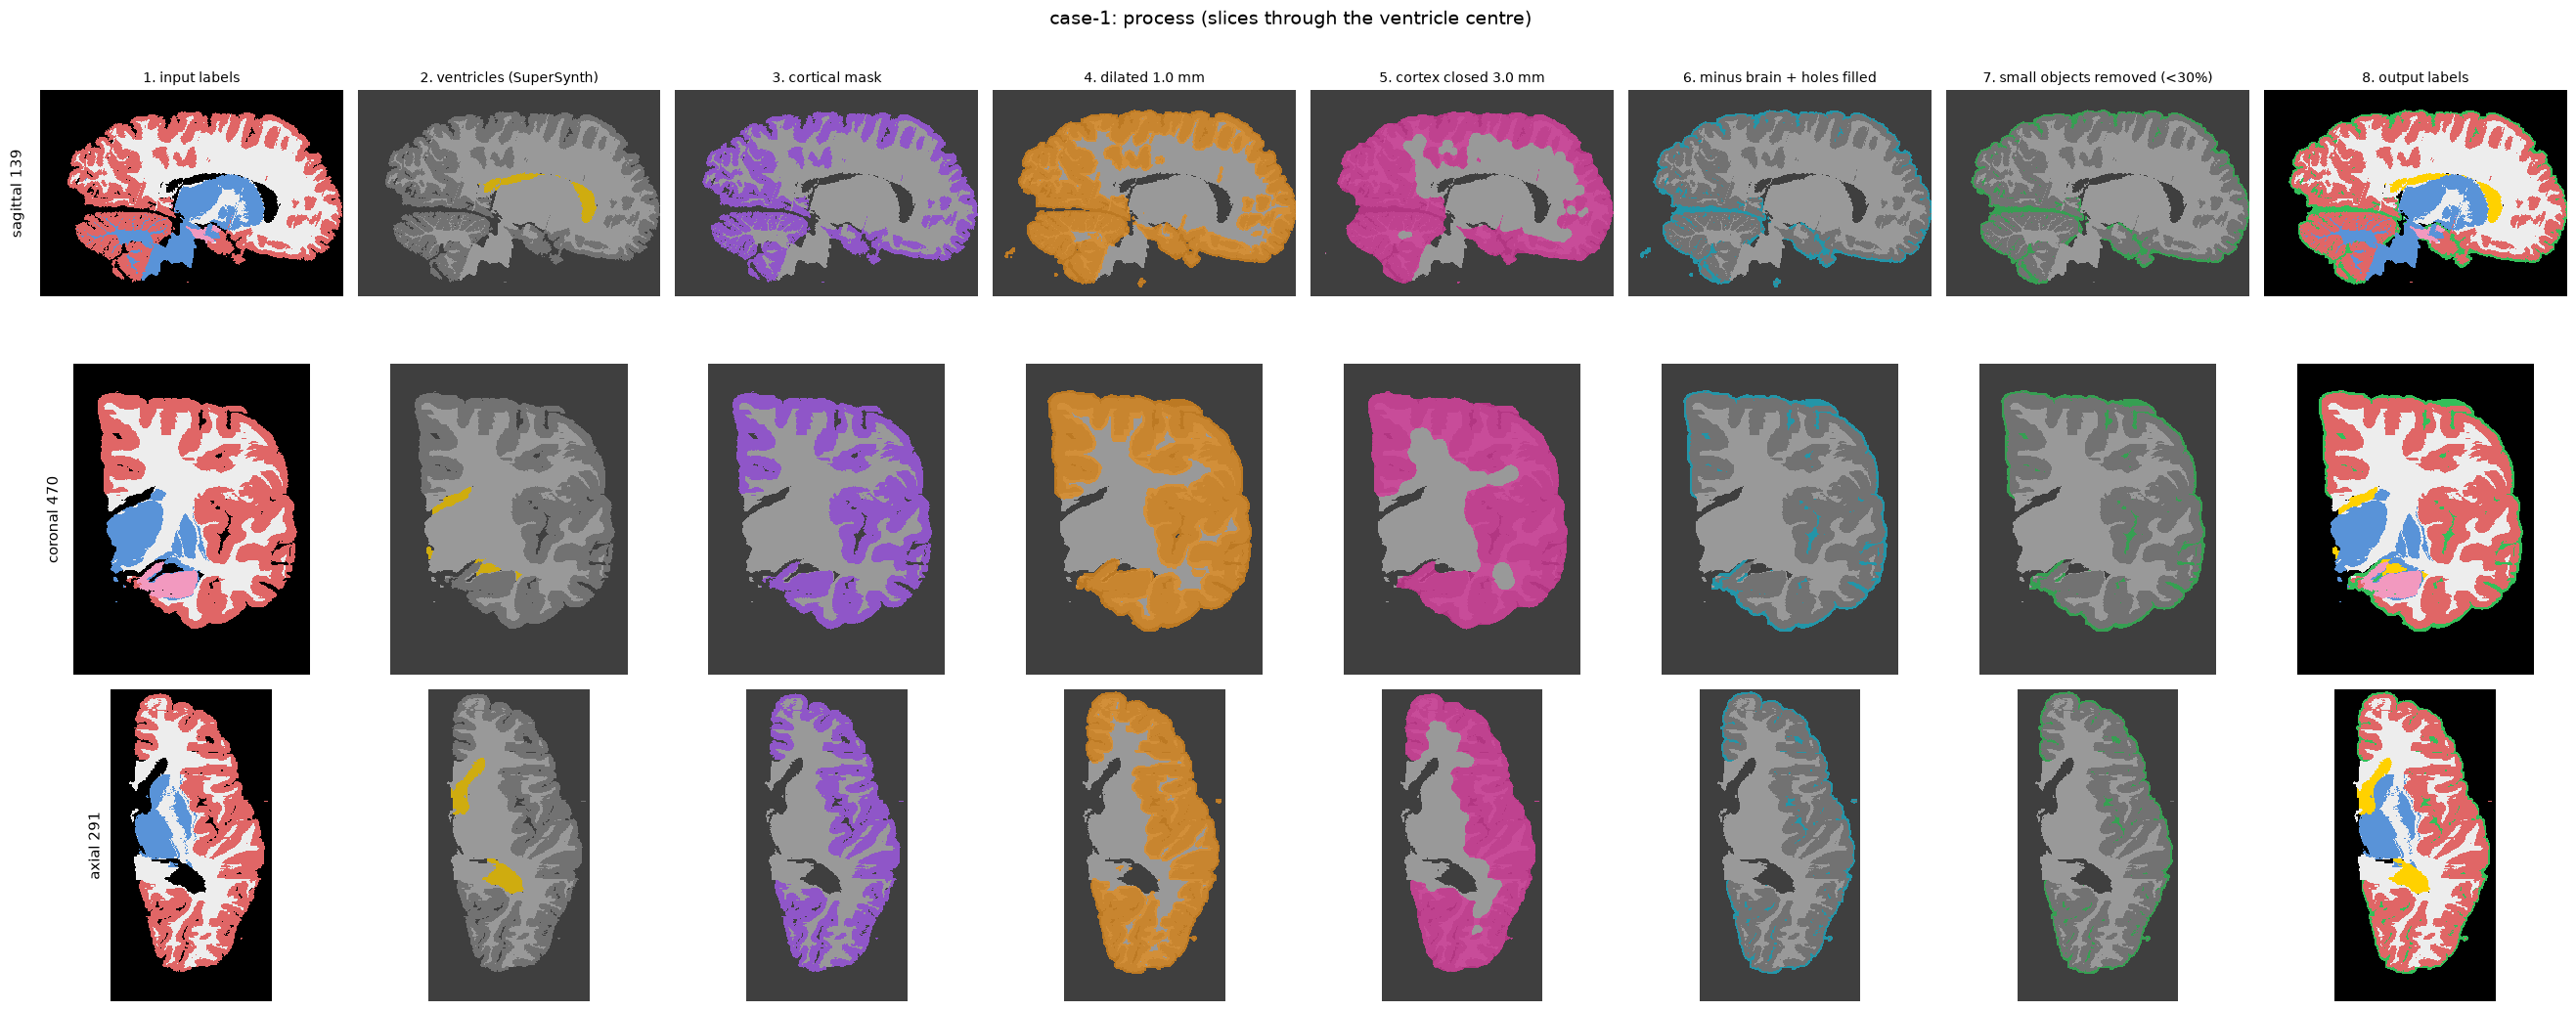

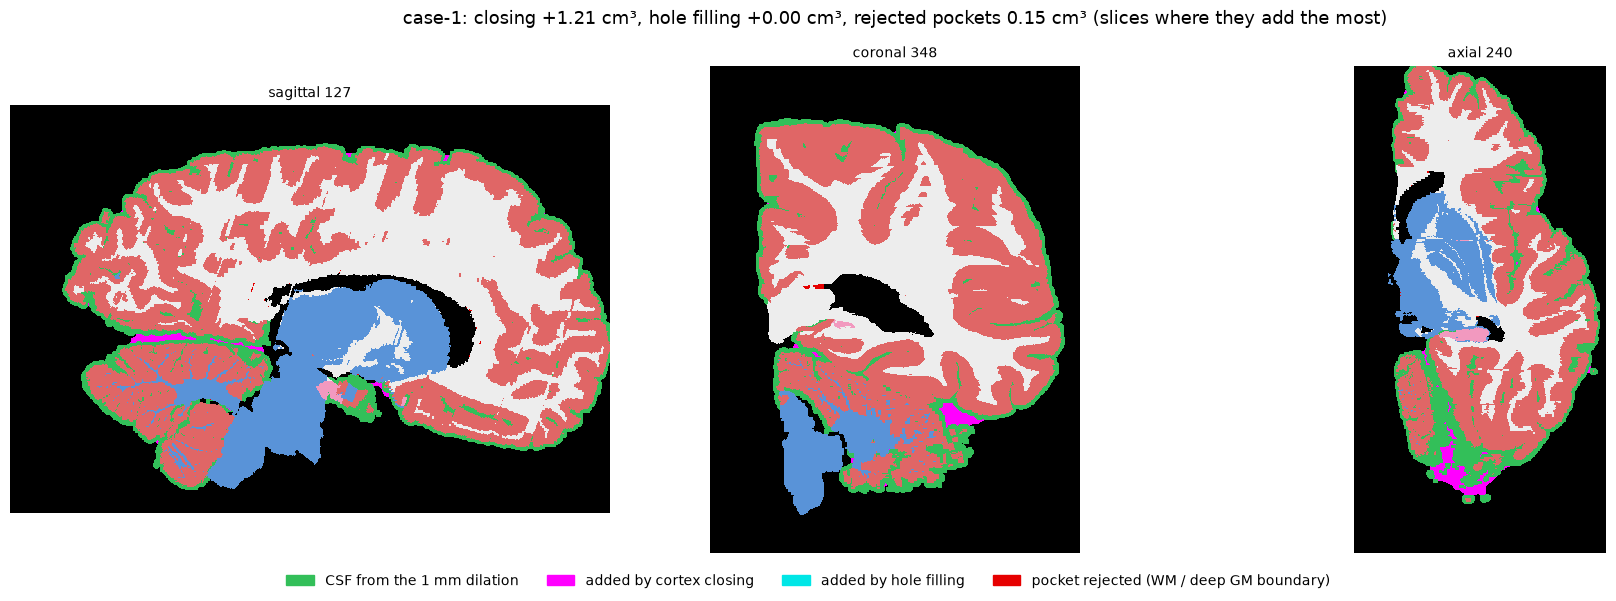

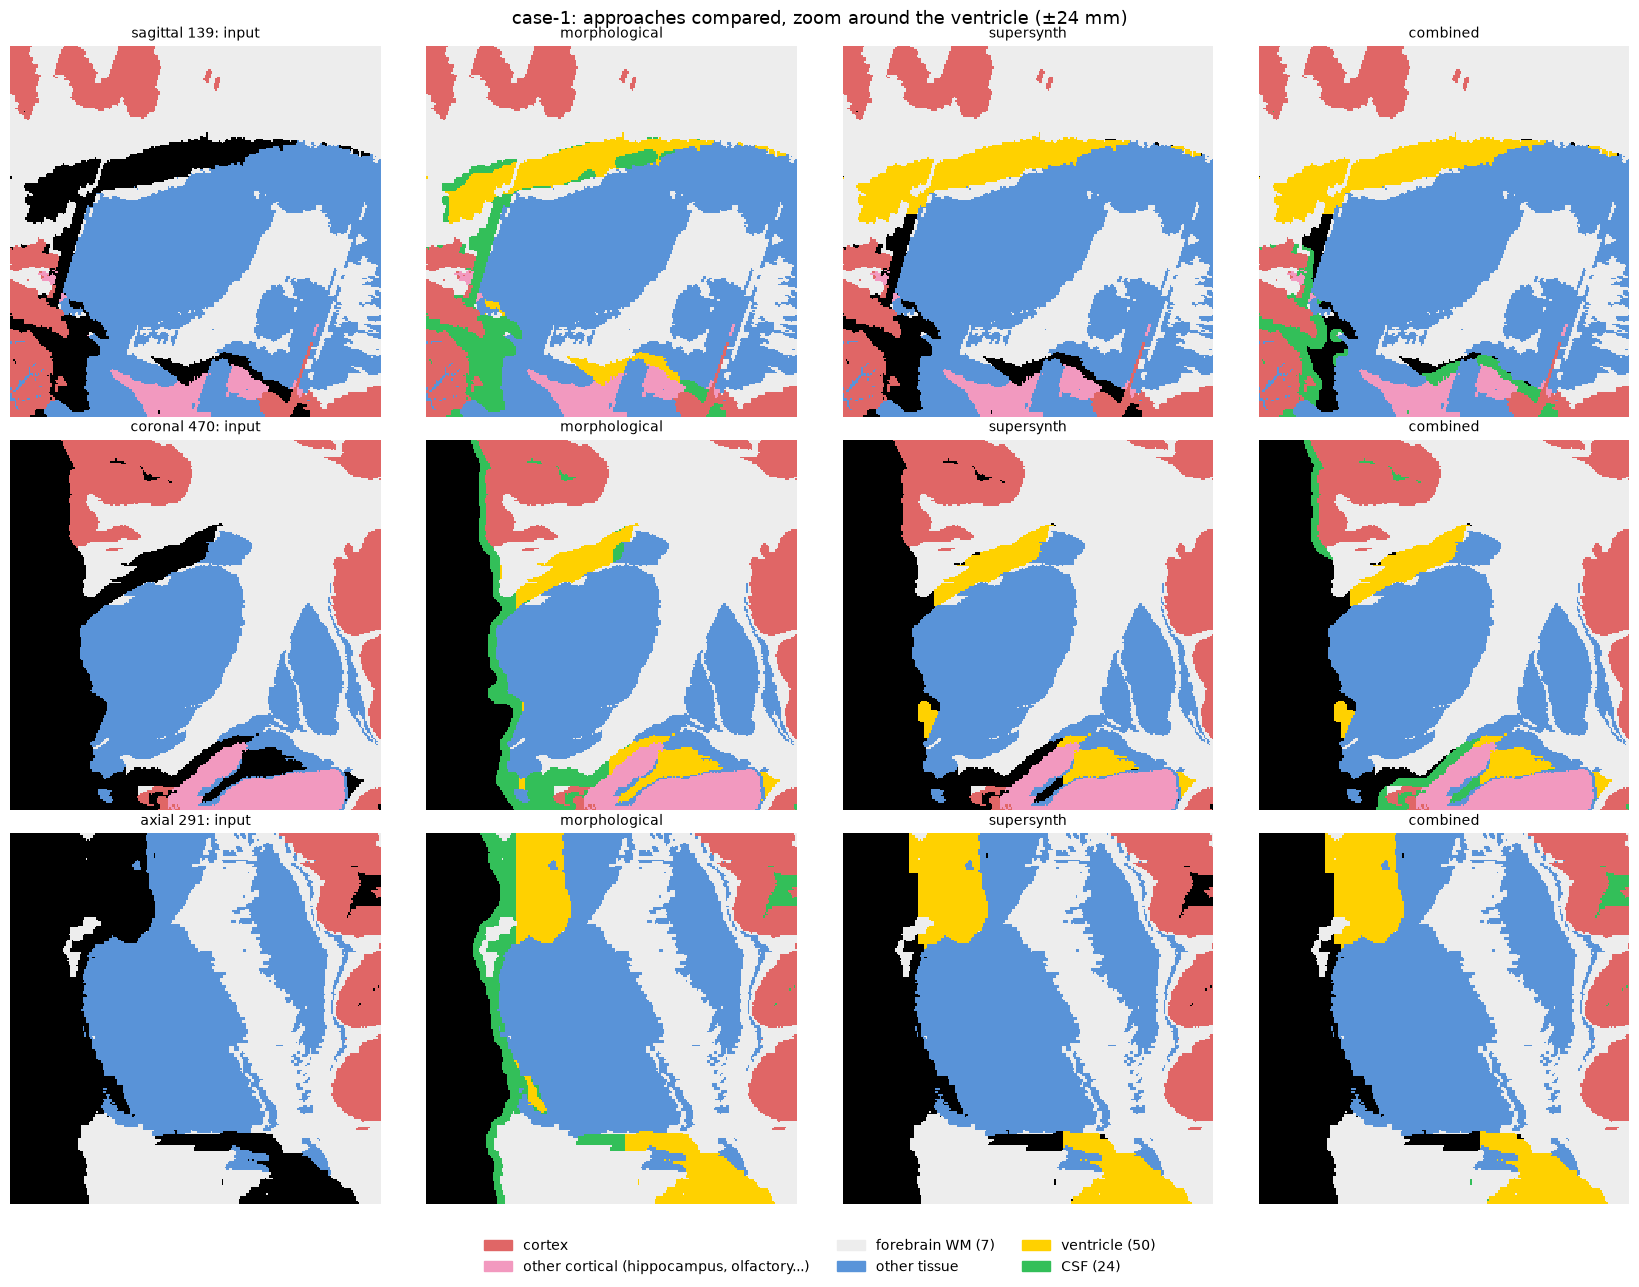

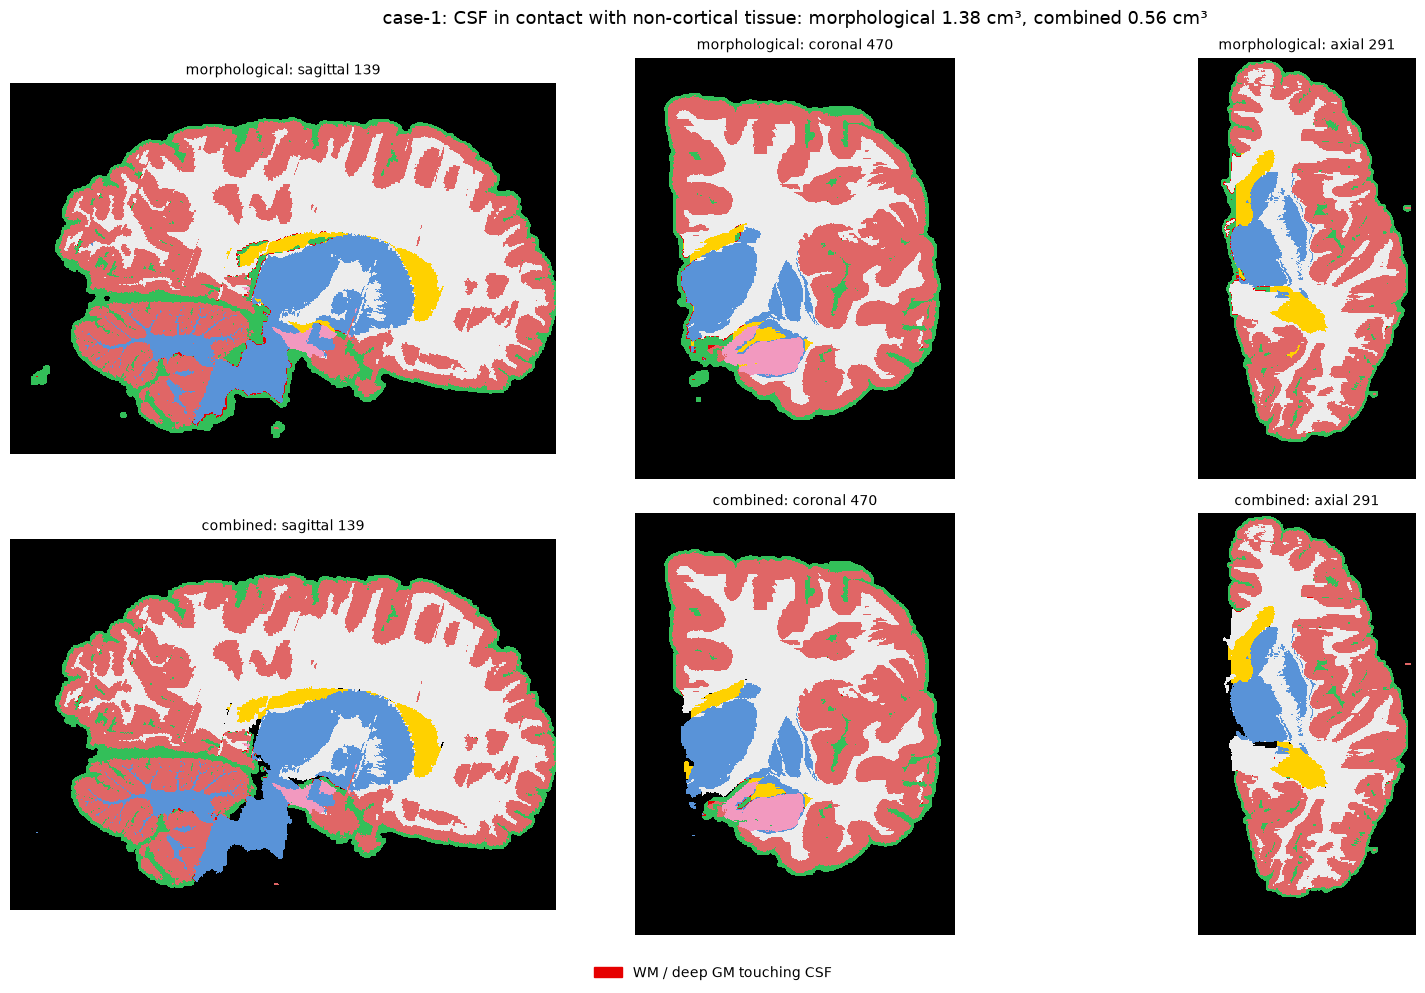

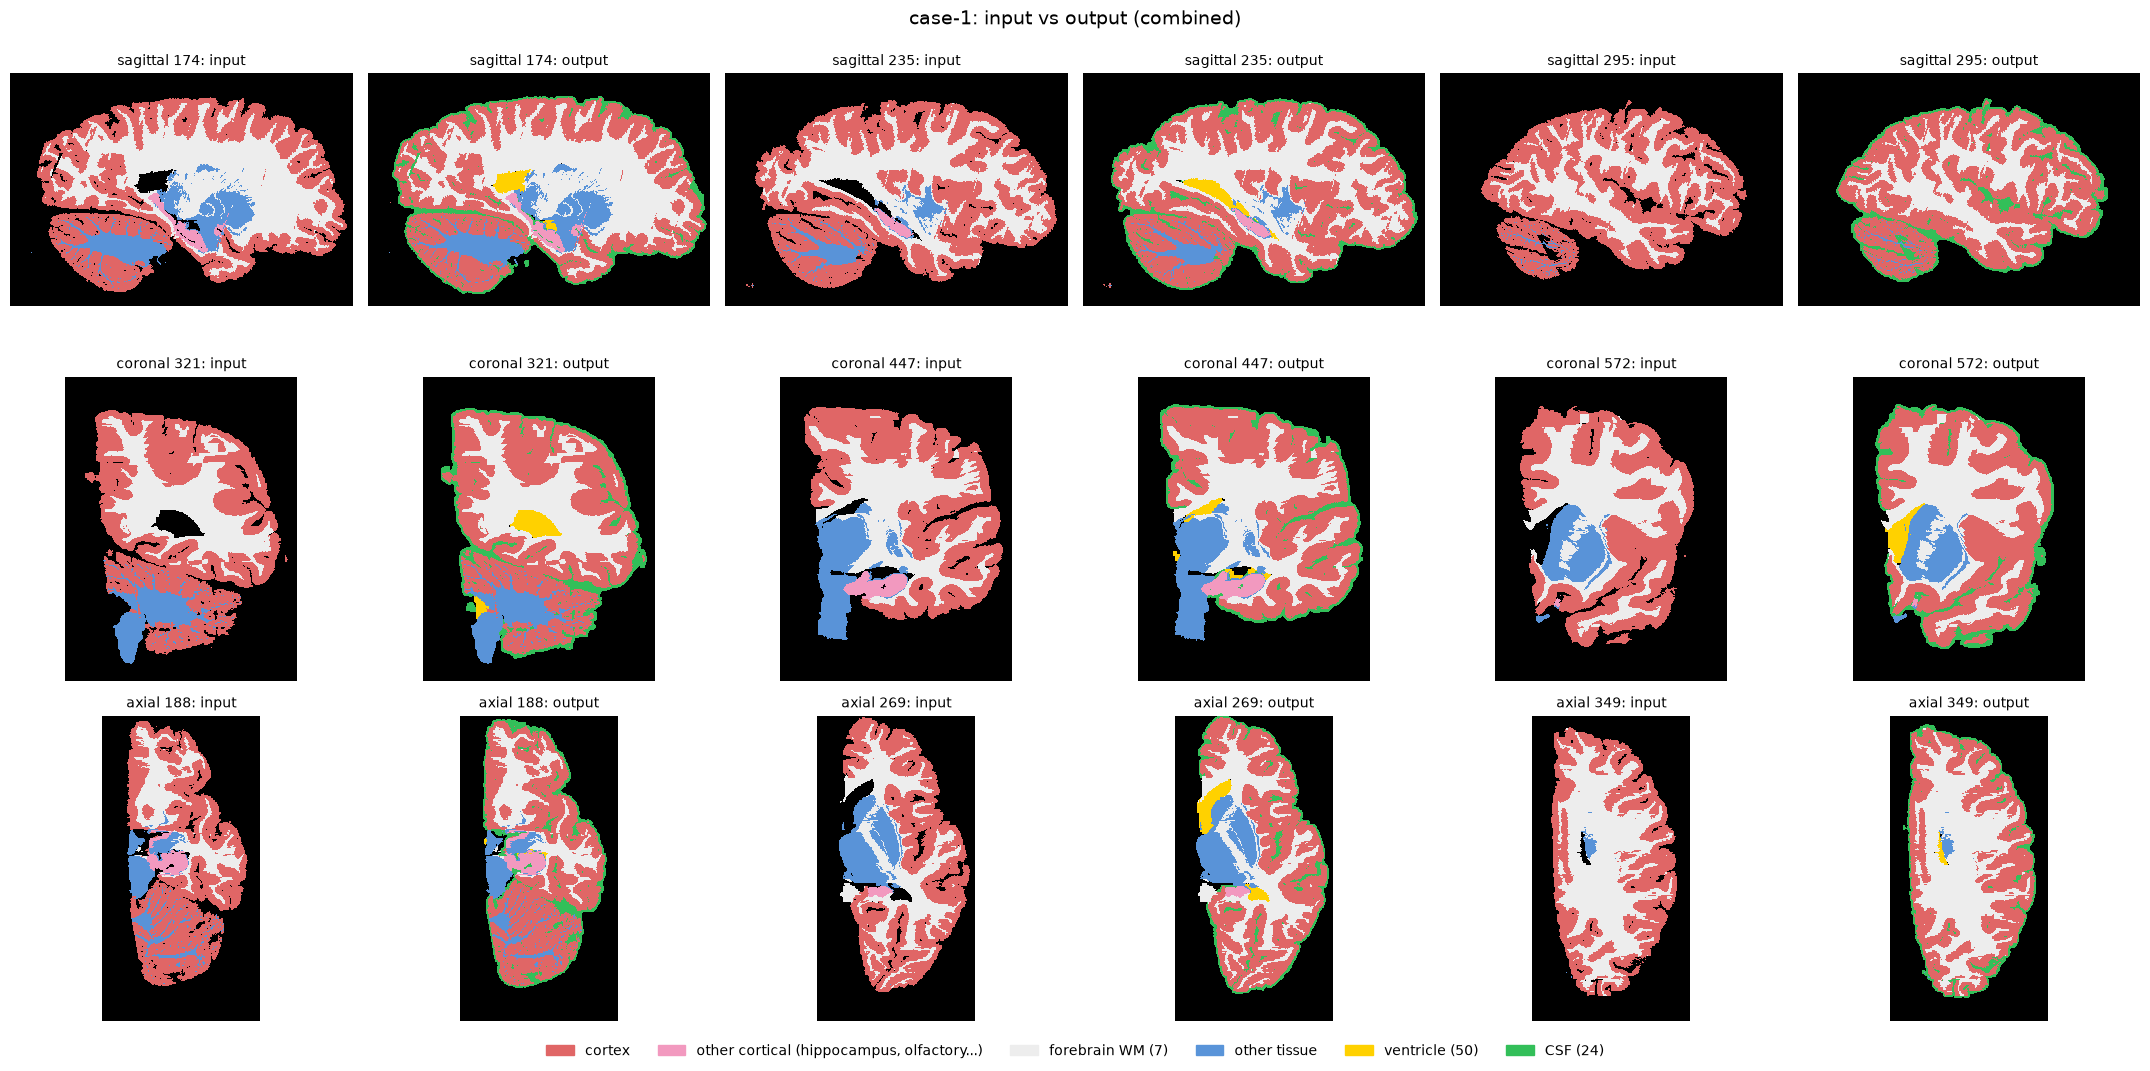

In [4]:
case = "case-1"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
plot_process(case, d)
plot_closing(case, d)
plot_compare(case, d)
plot_contact(case, d)
plot_result(case, d)
del d

### case-2

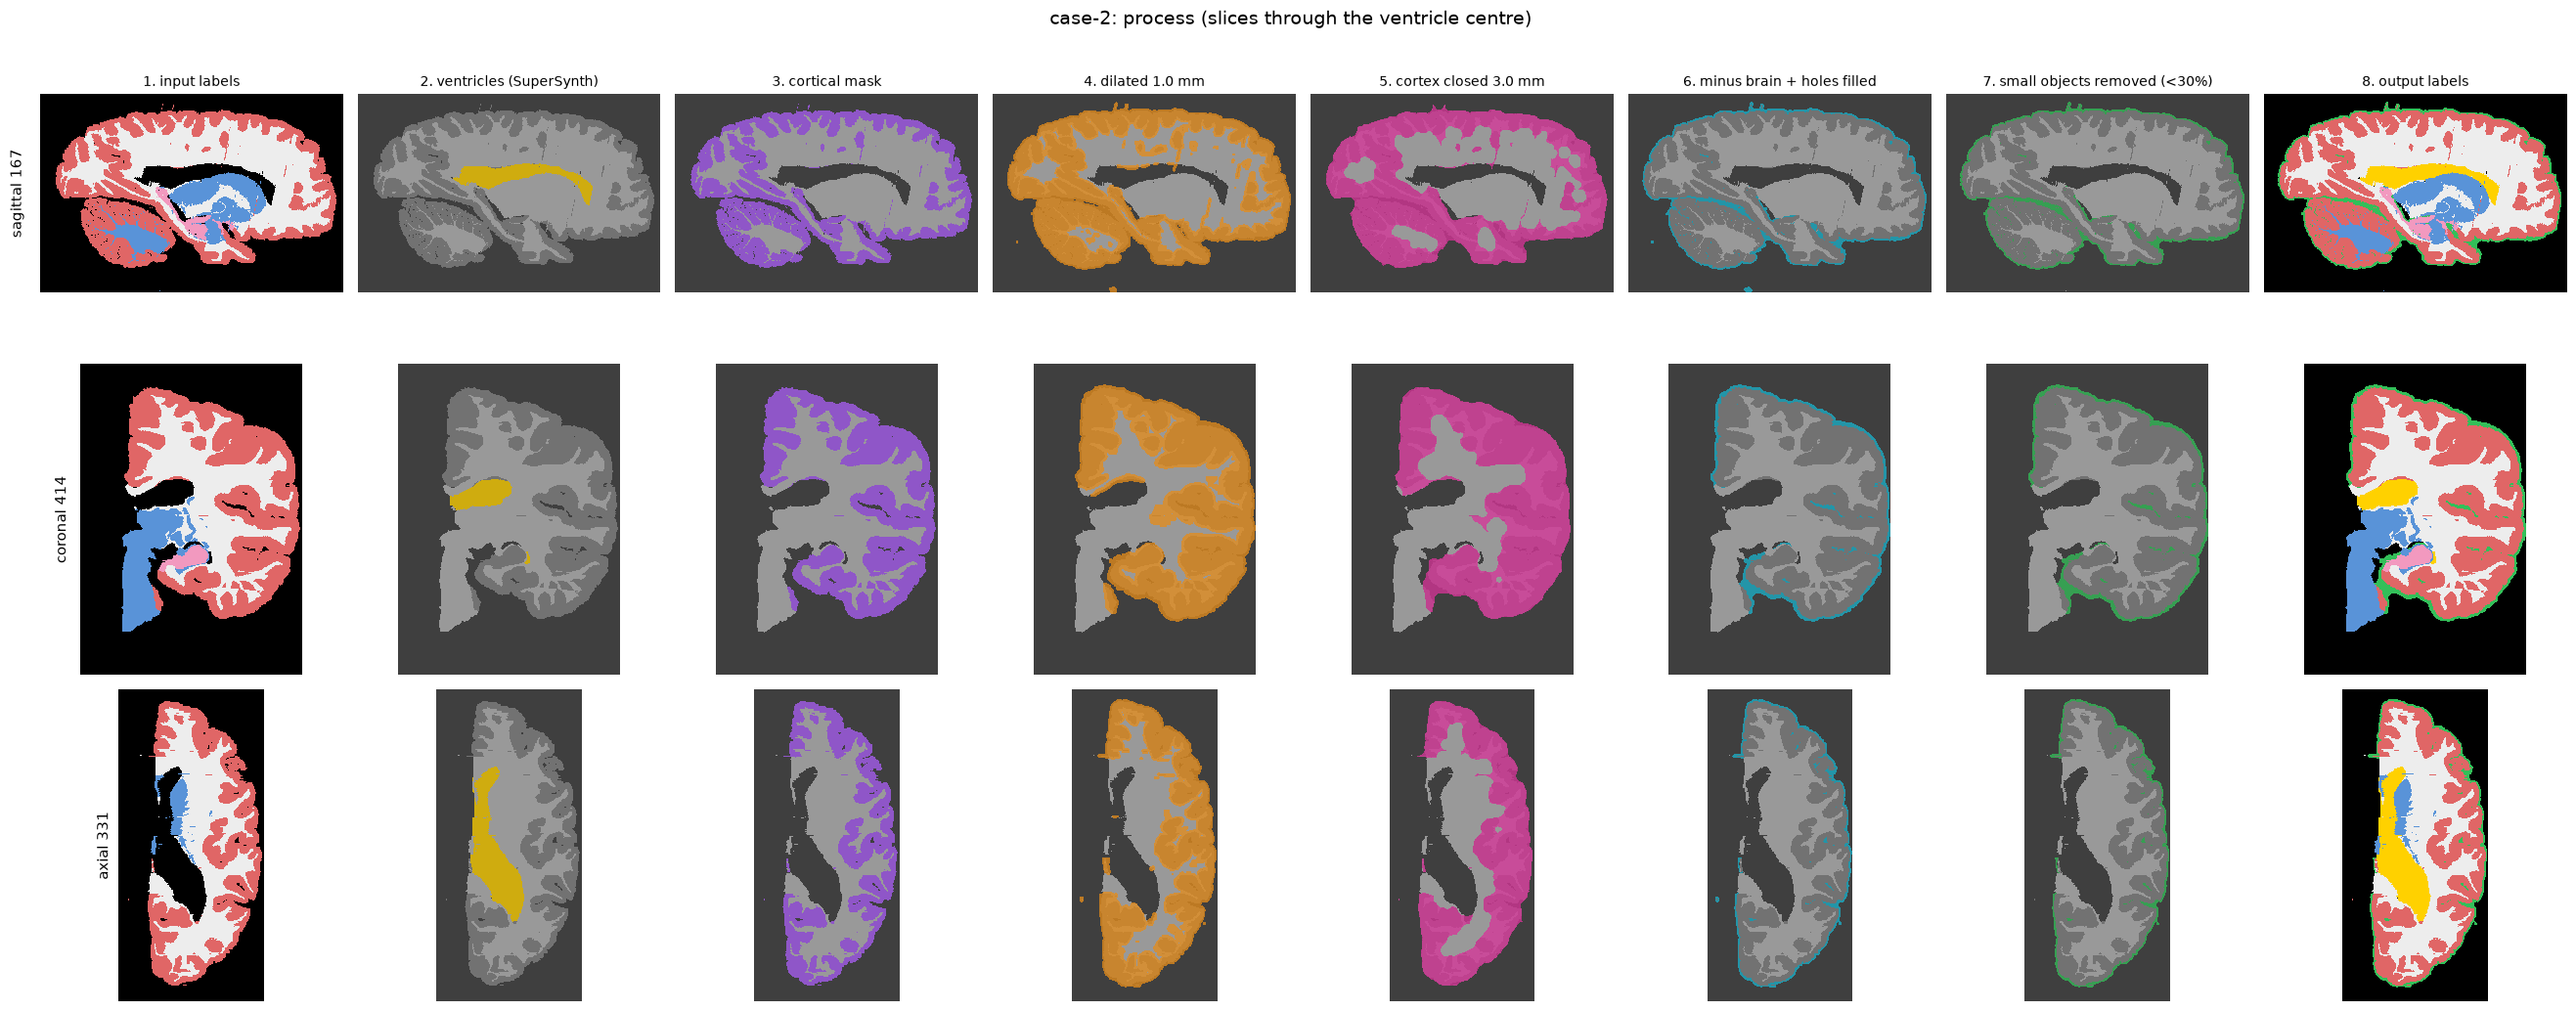

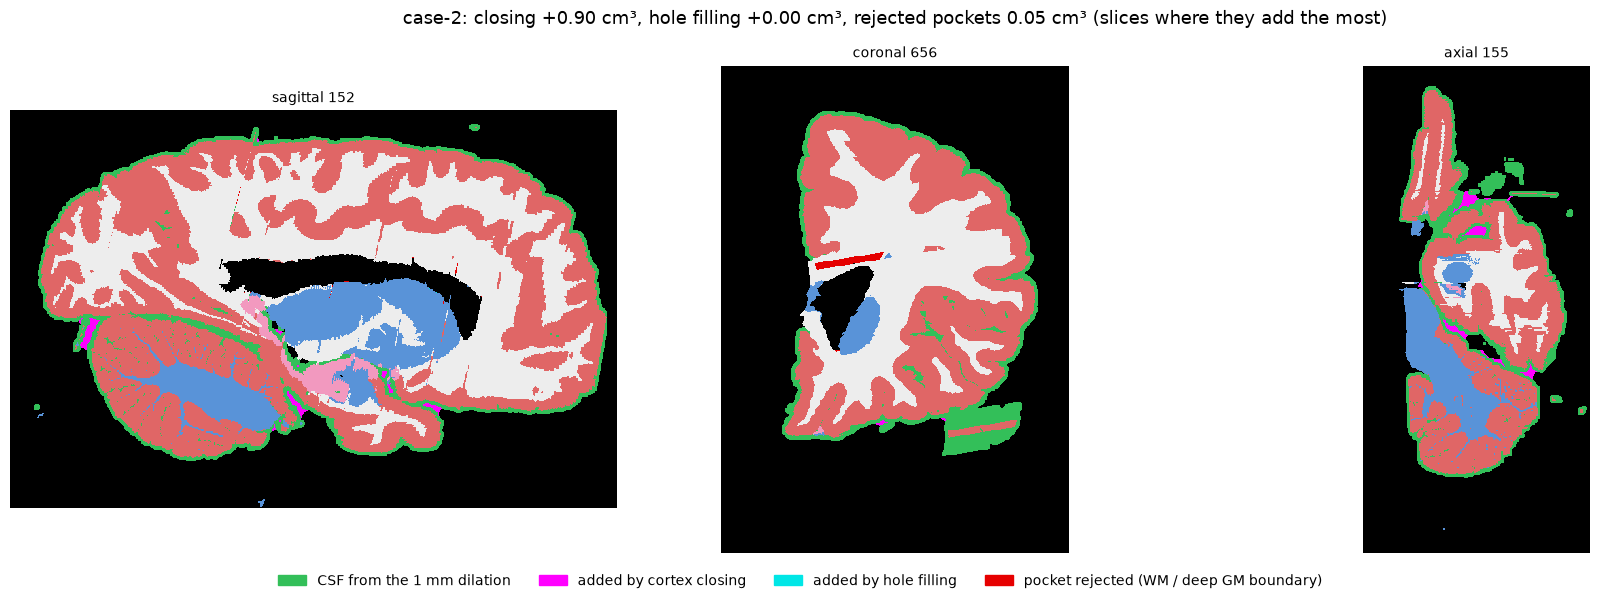

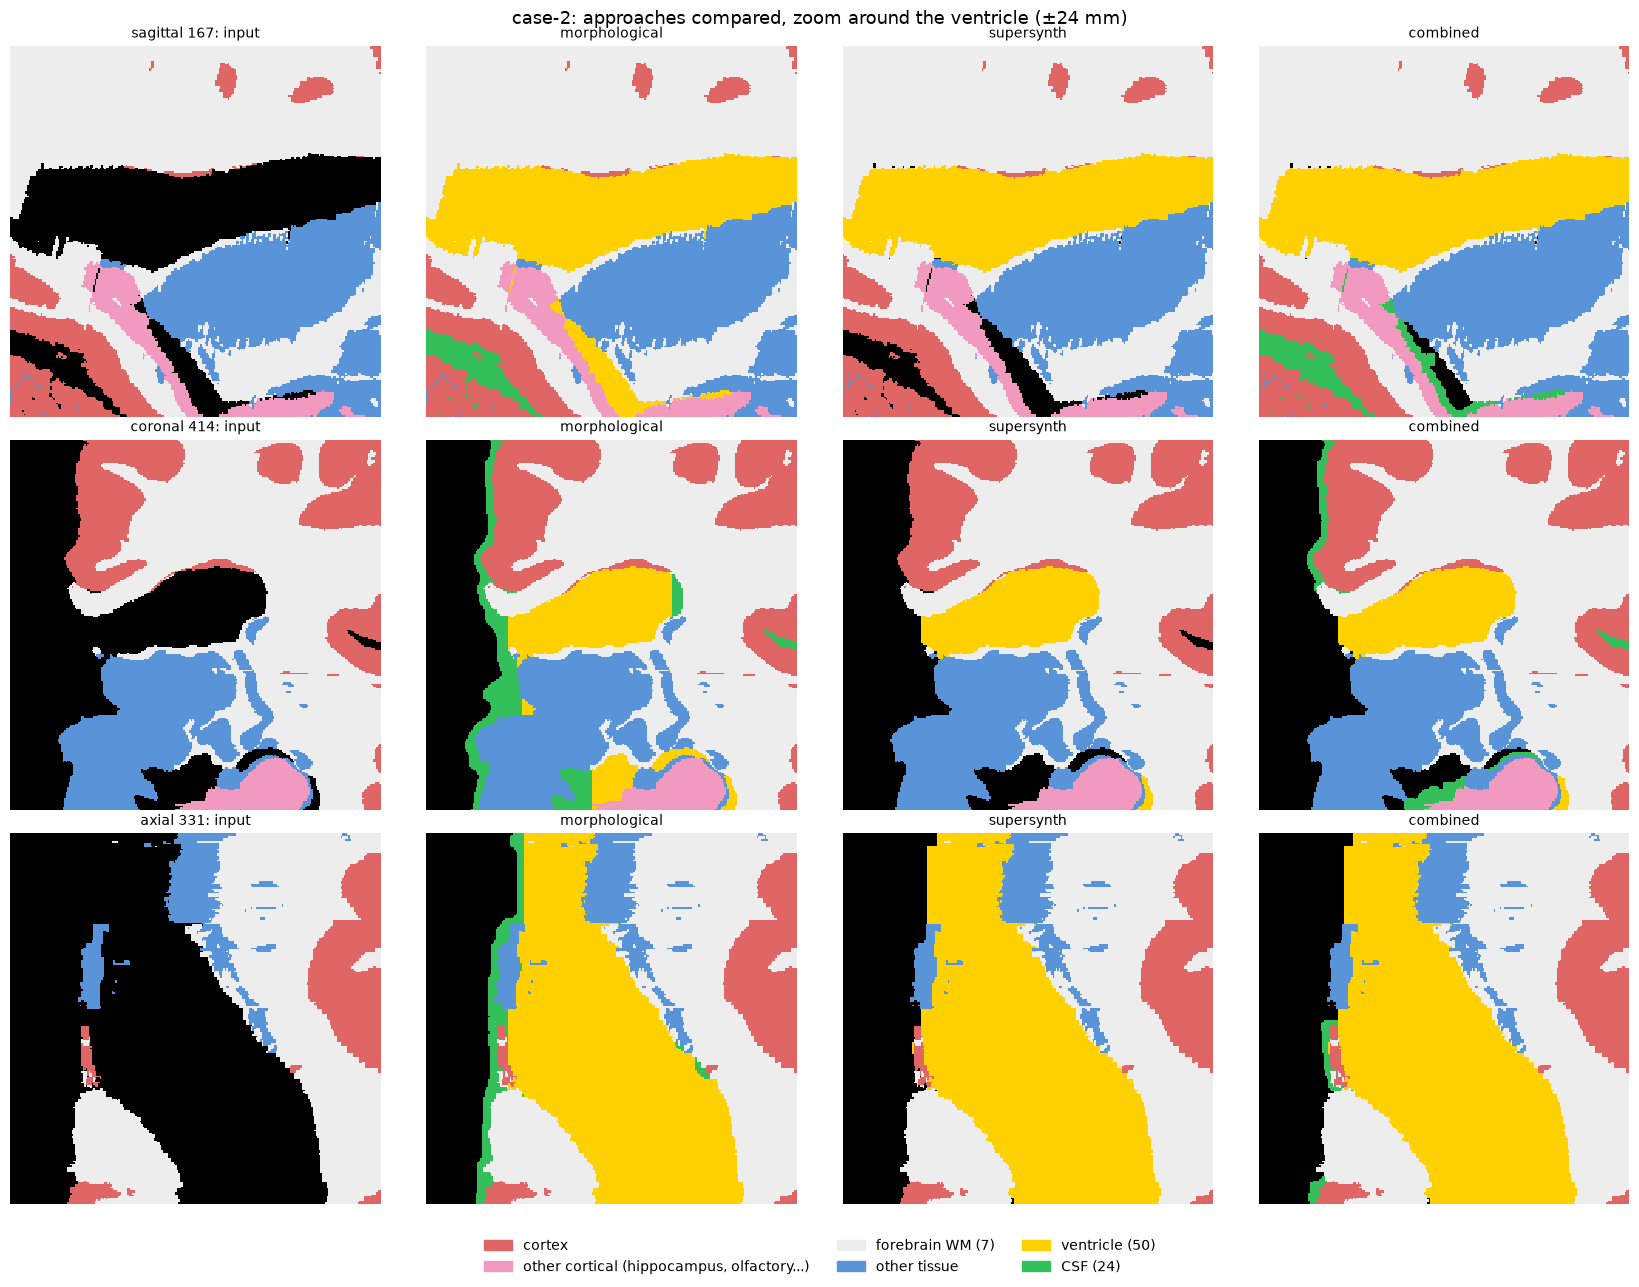

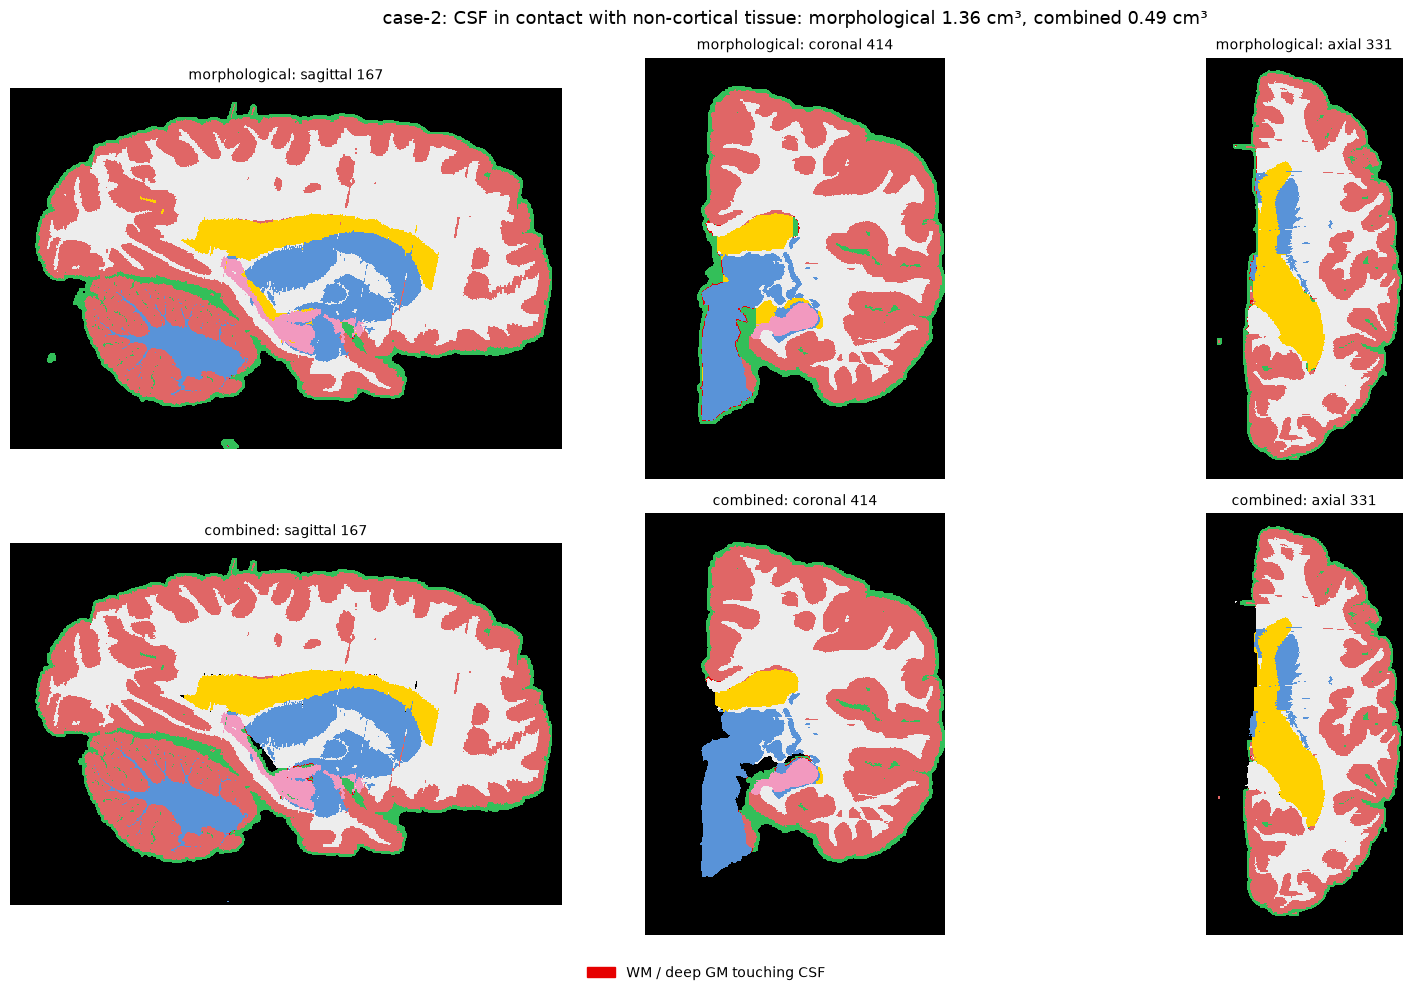

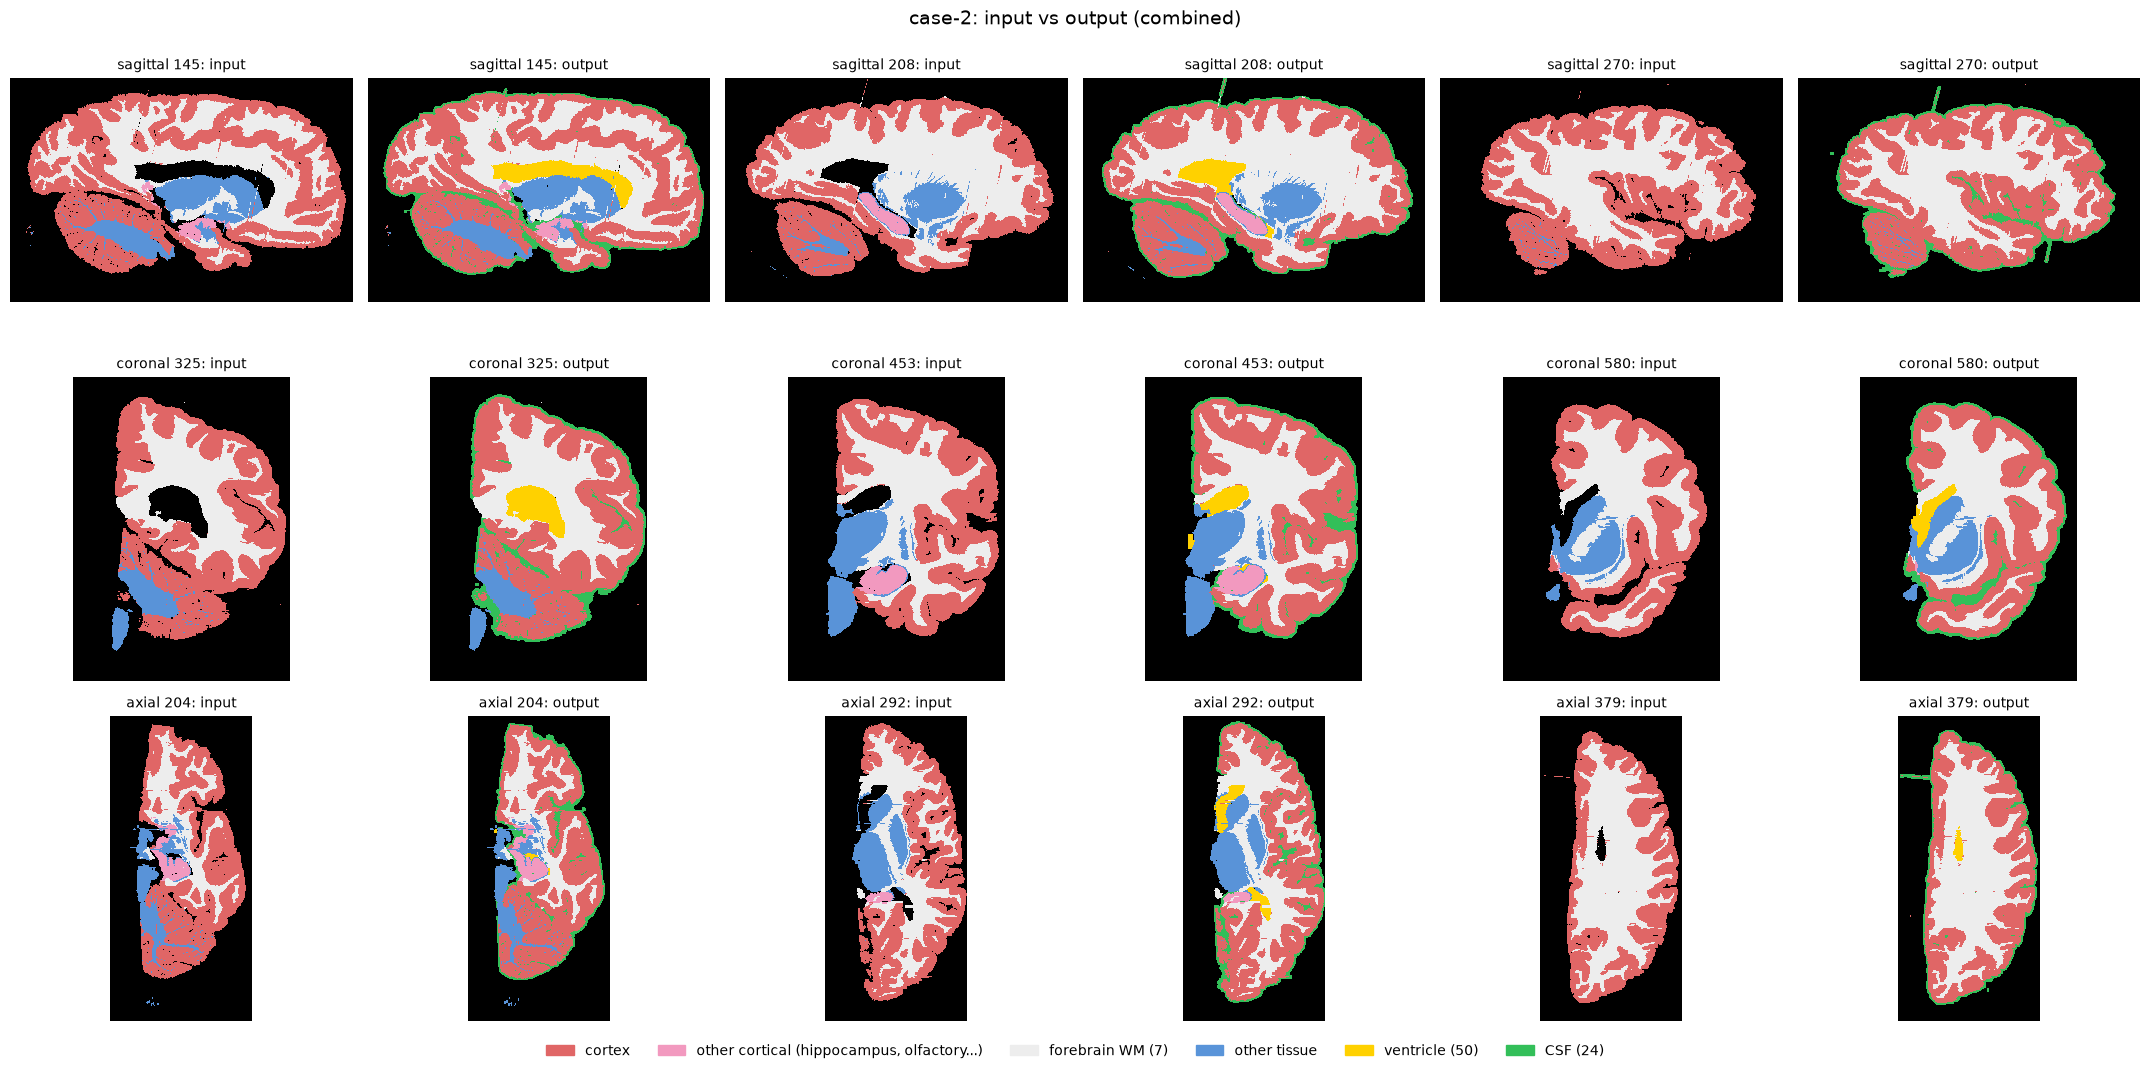

In [5]:
case = "case-2"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
plot_process(case, d)
plot_closing(case, d)
plot_compare(case, d)
plot_contact(case, d)
plot_result(case, d)
del d

### case-3

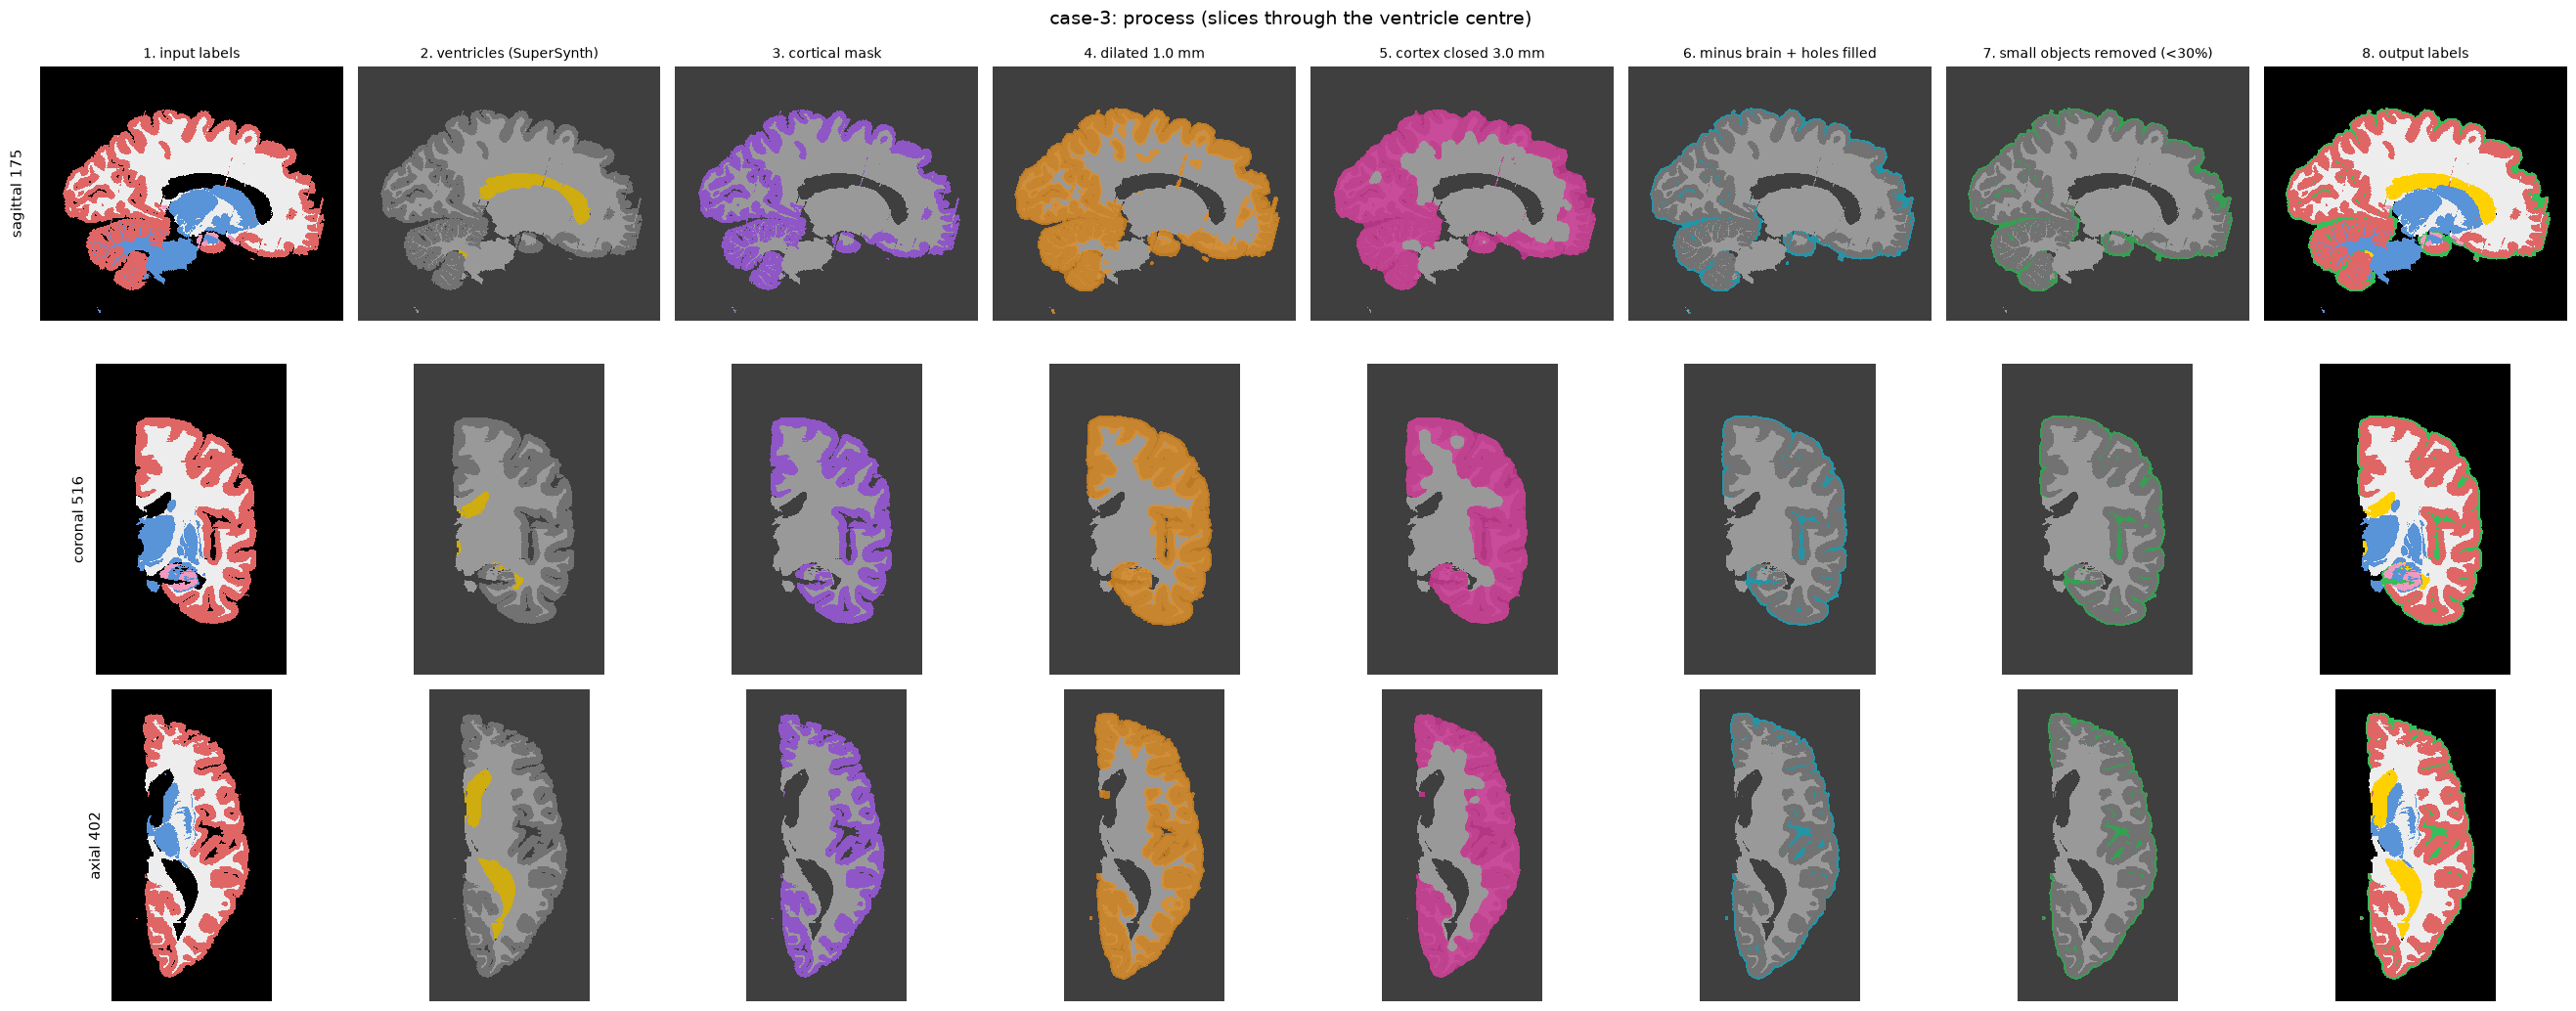

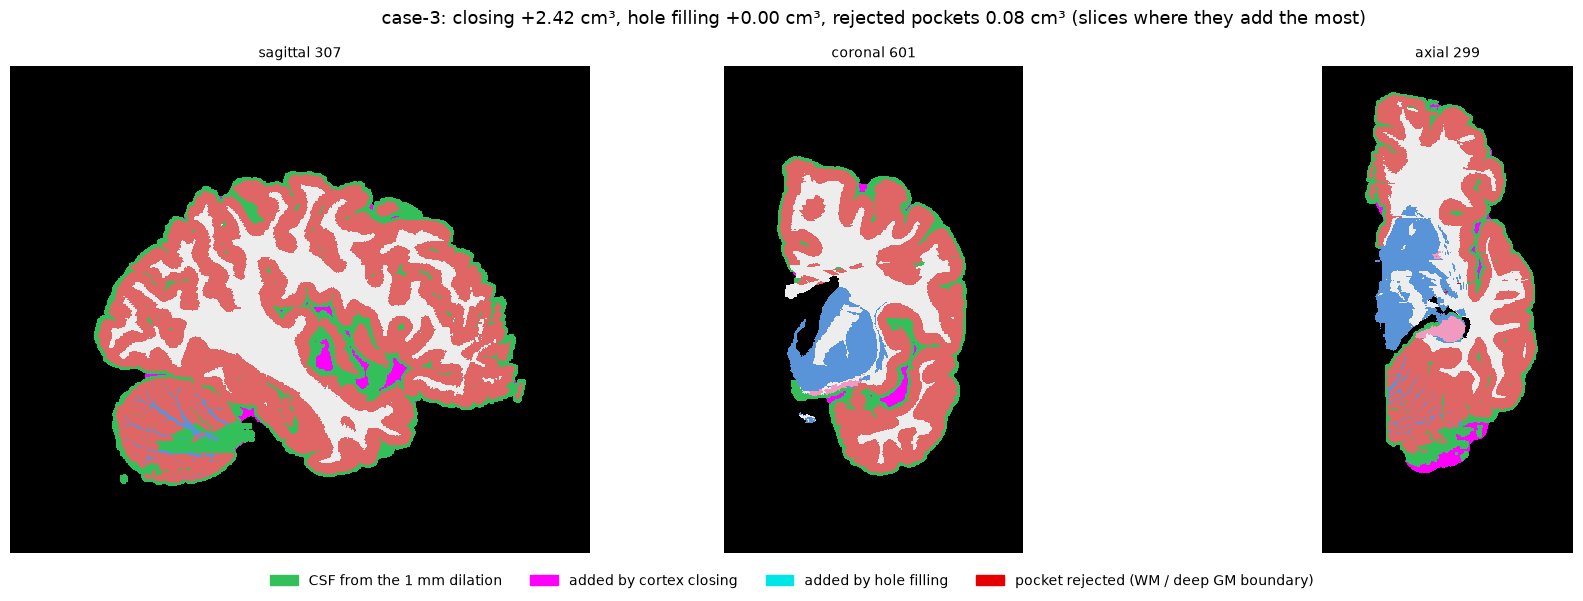

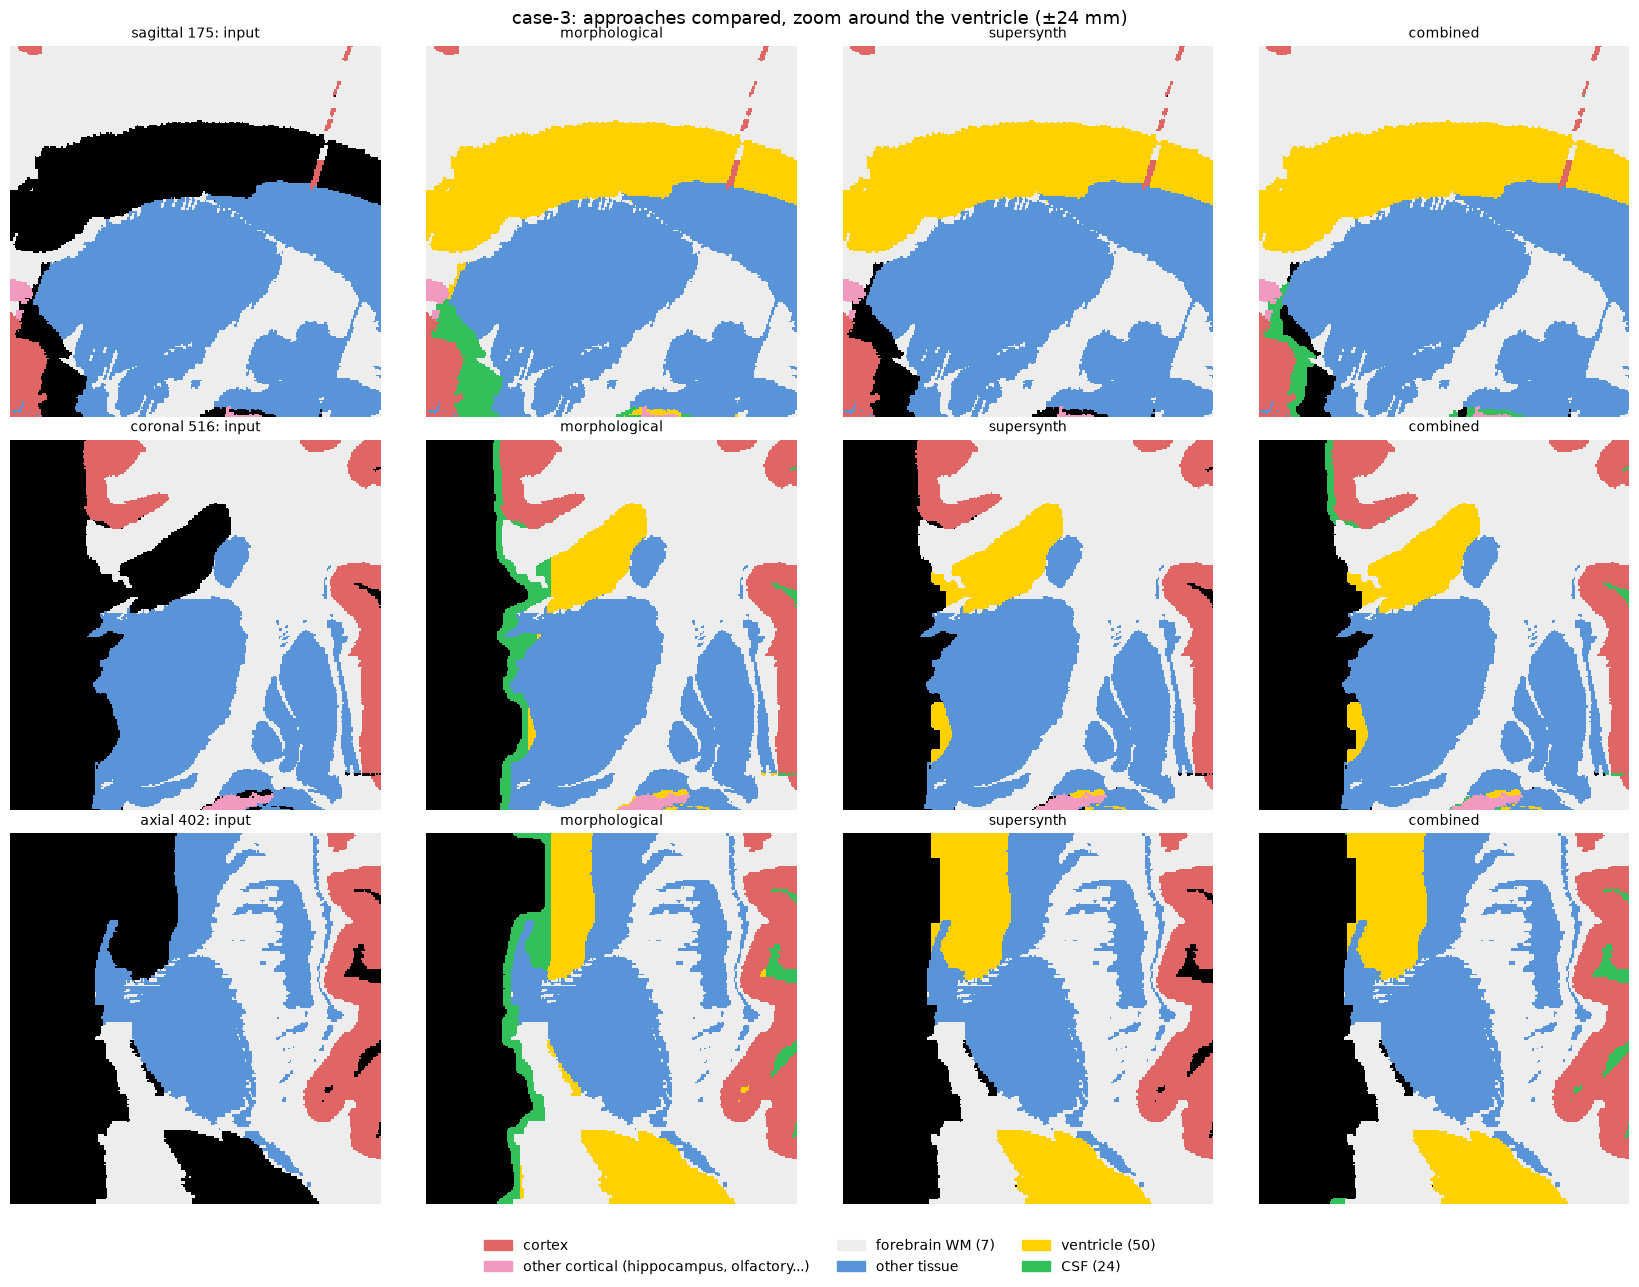

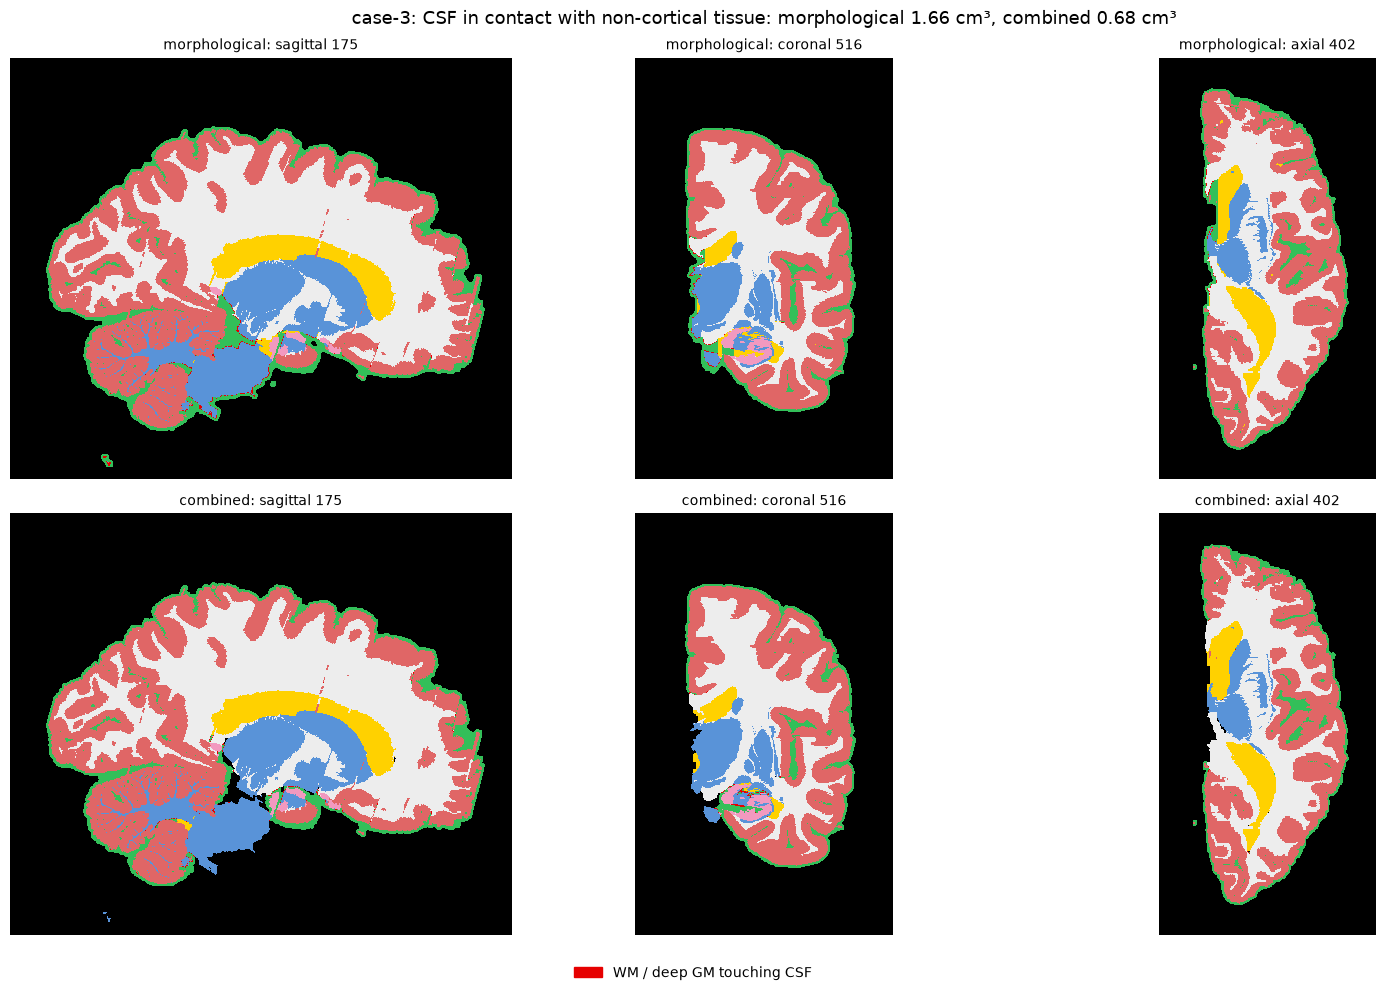

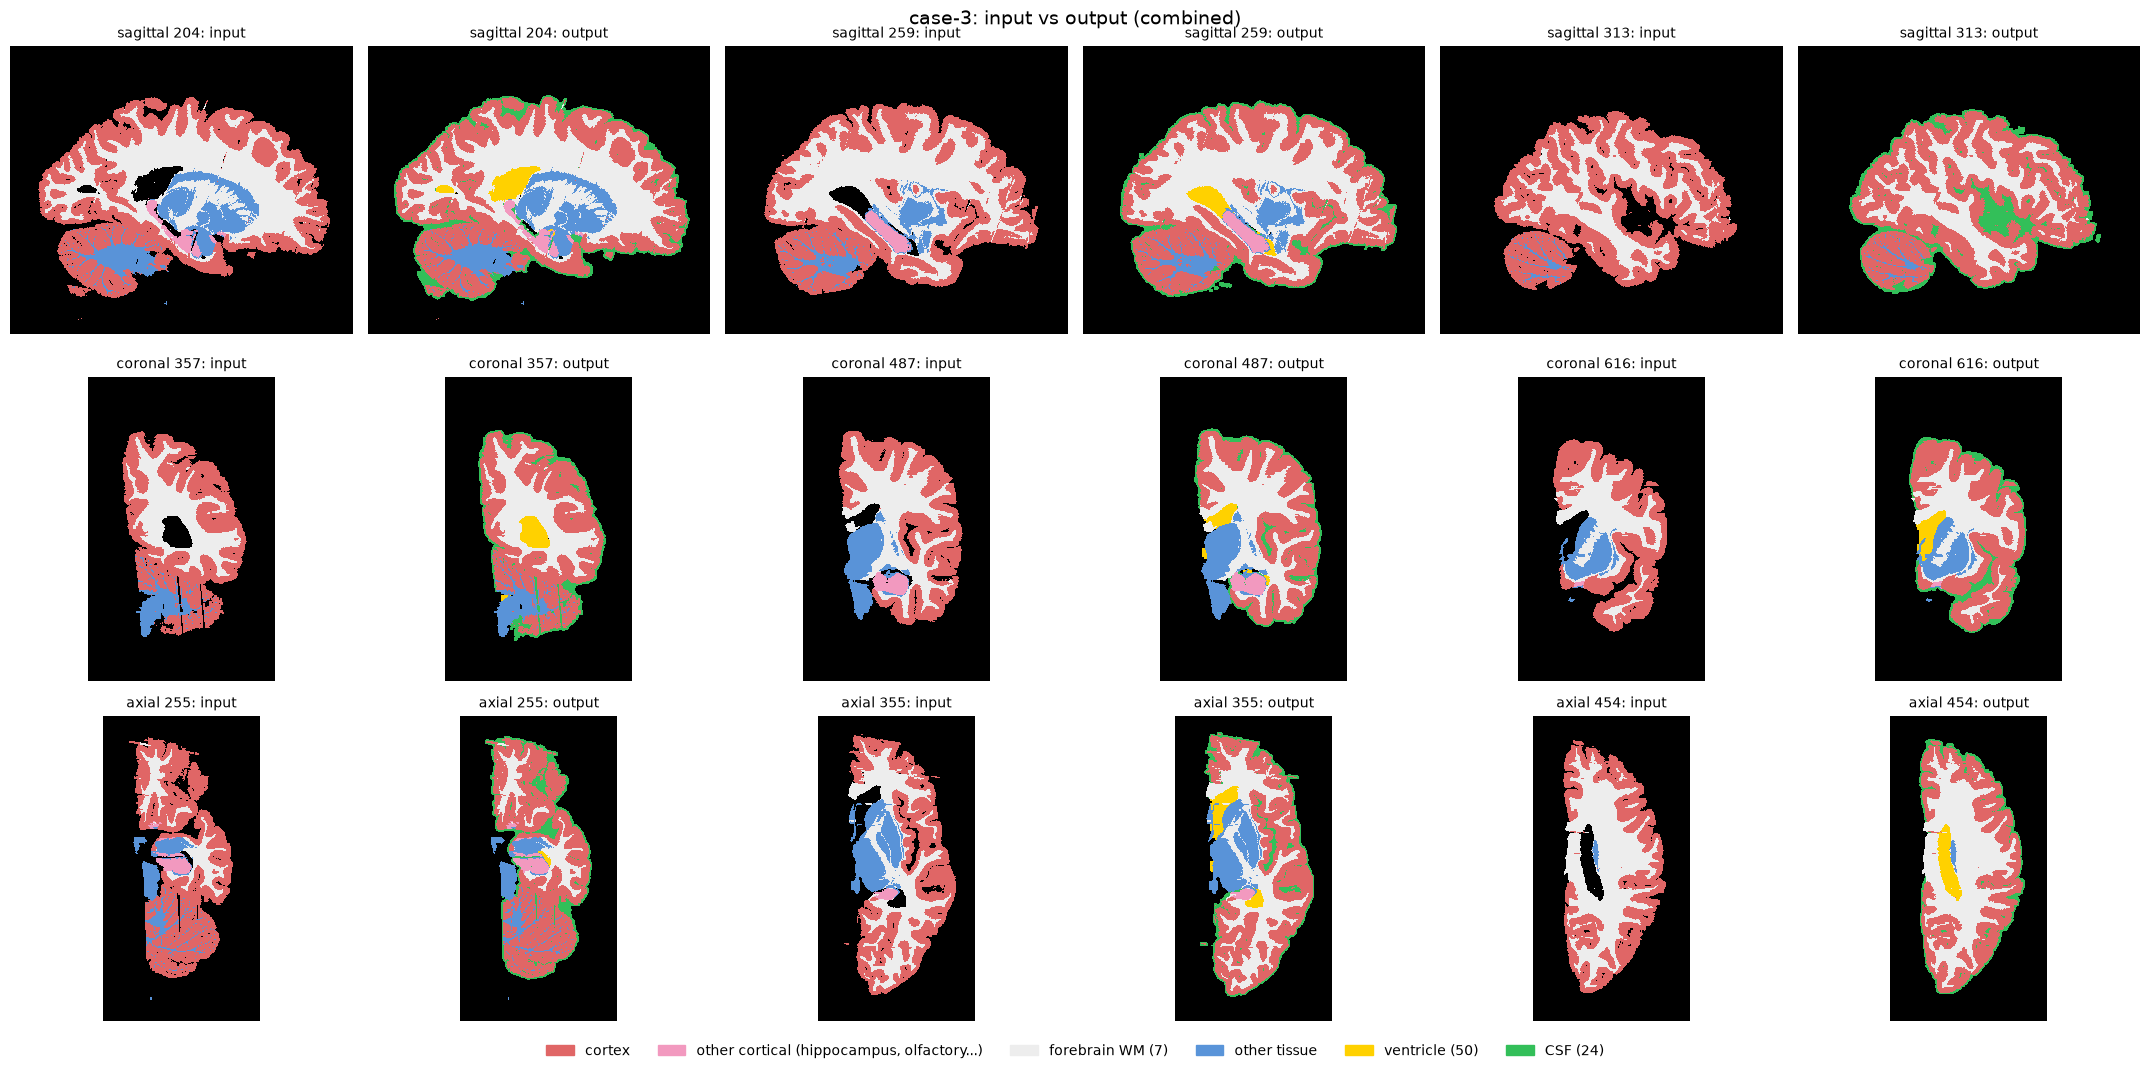

In [6]:
case = "case-3"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
plot_process(case, d)
plot_closing(case, d)
plot_compare(case, d)
plot_contact(case, d)
plot_result(case, d)
del d

### case-4

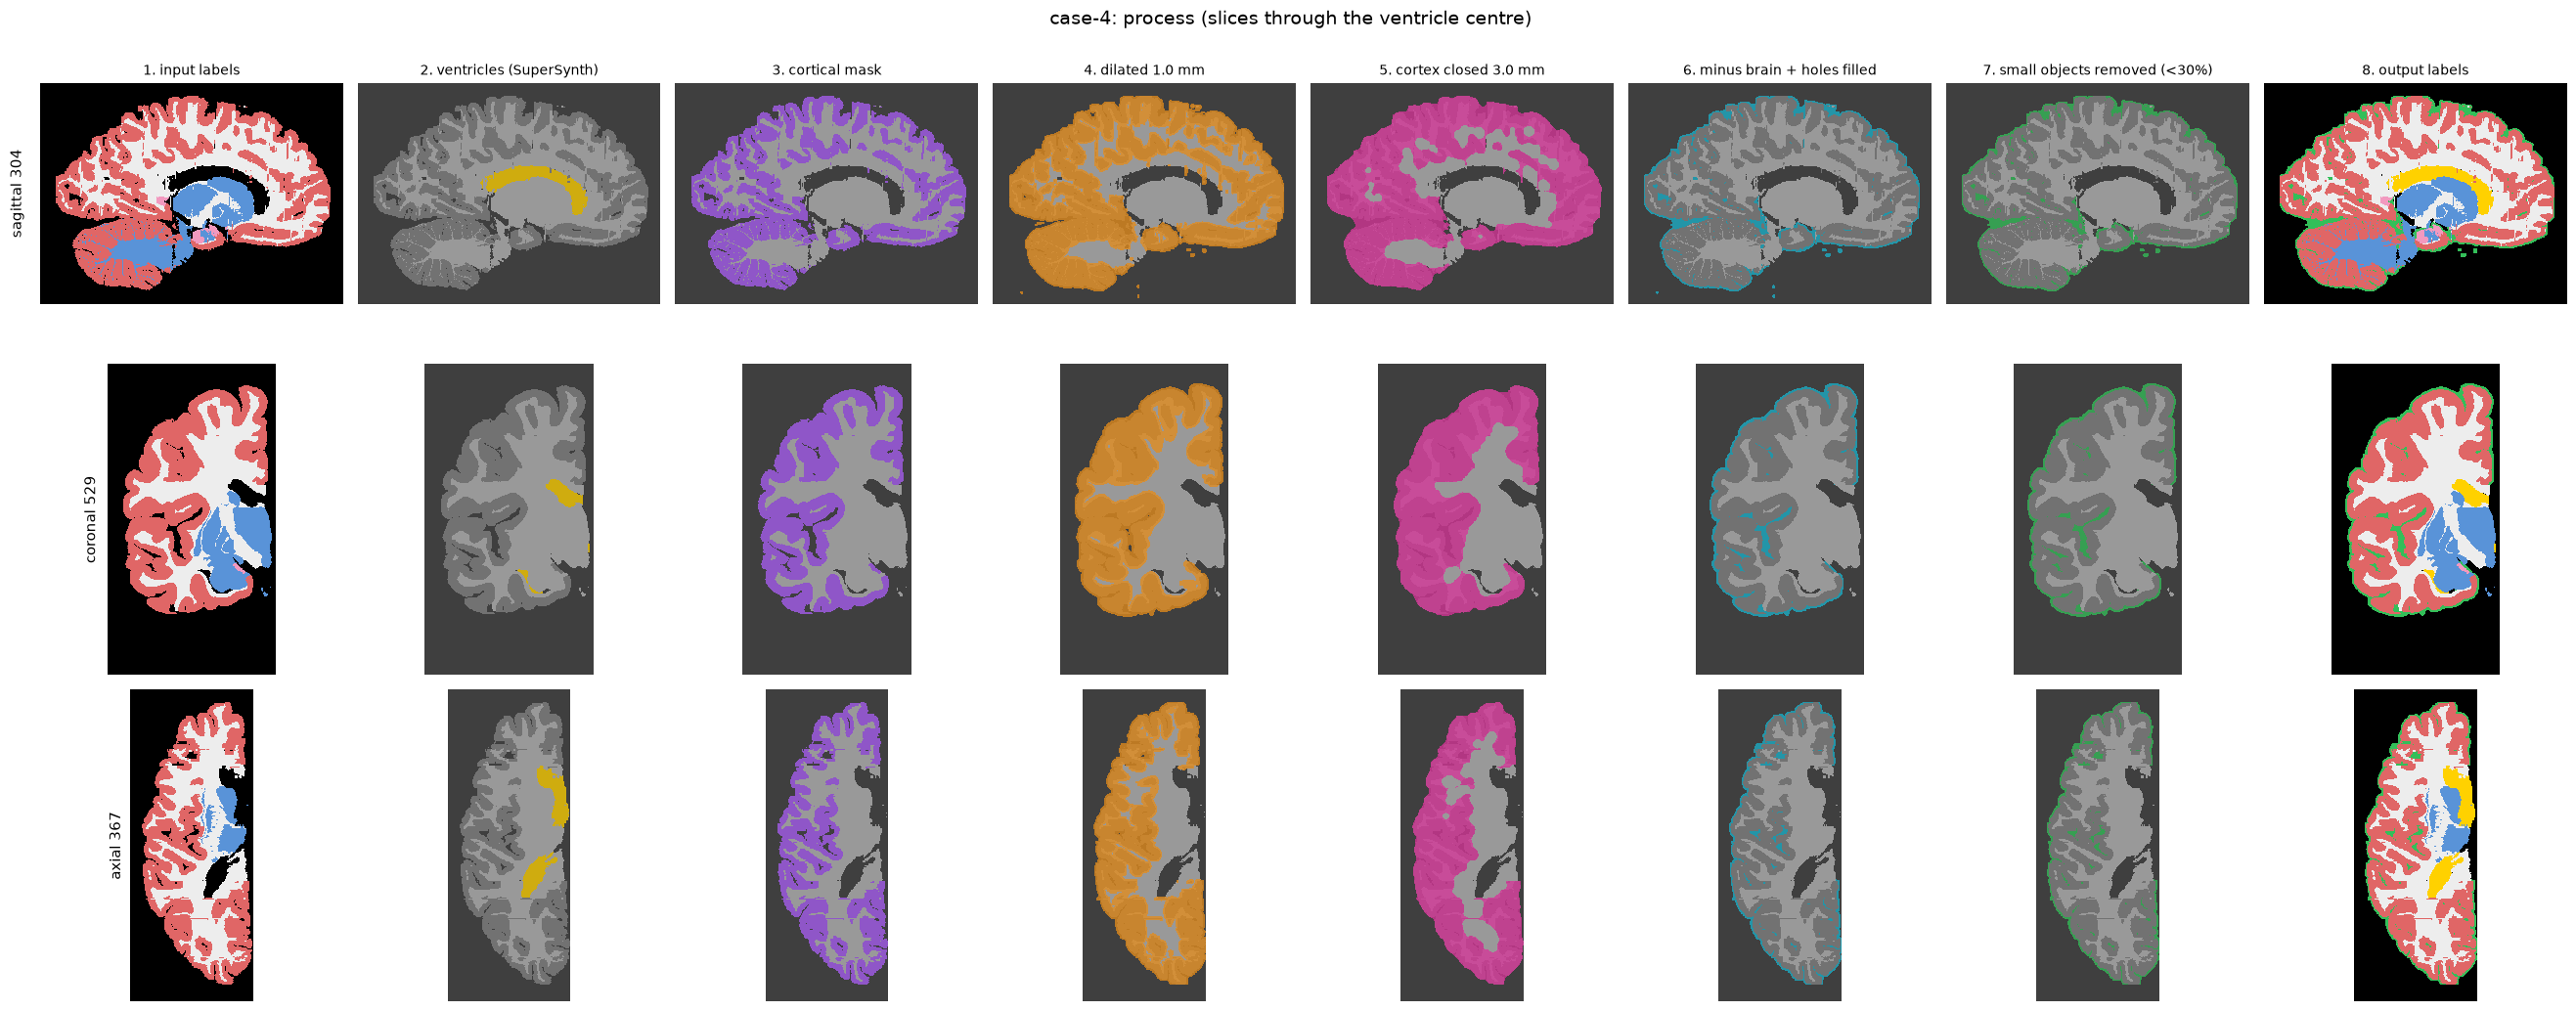

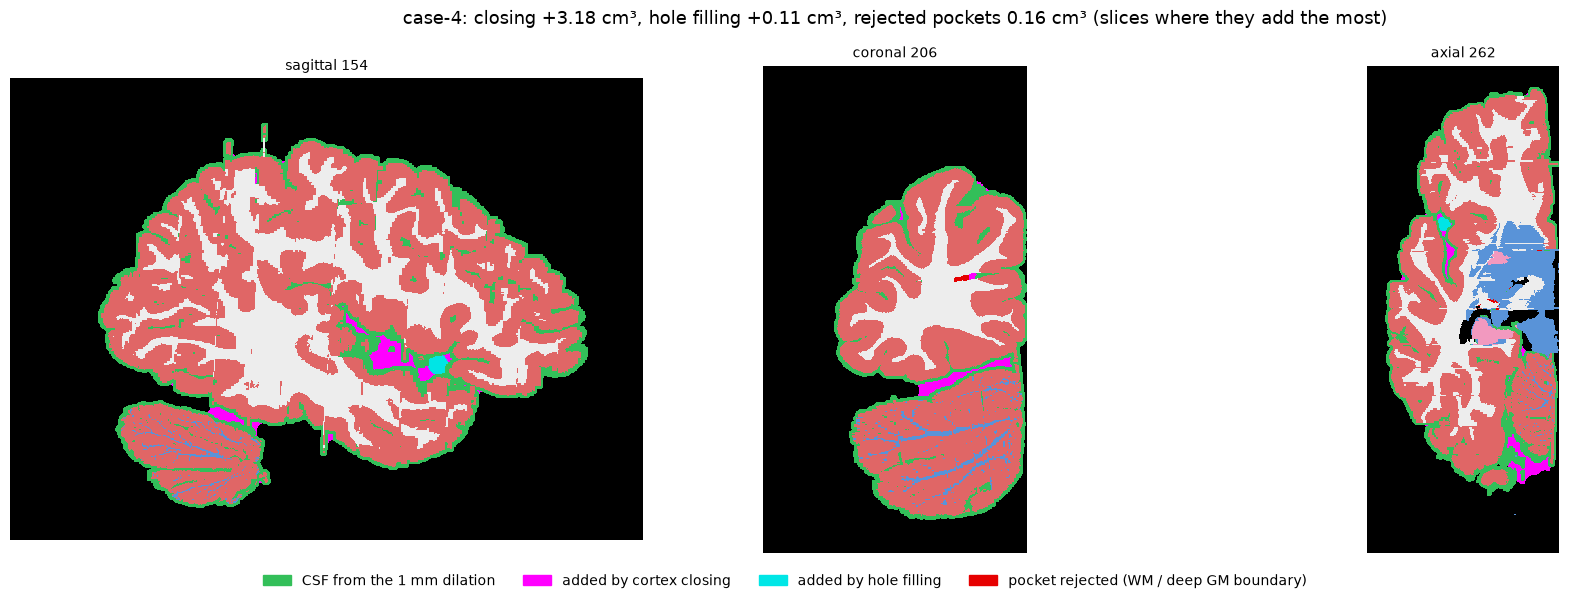

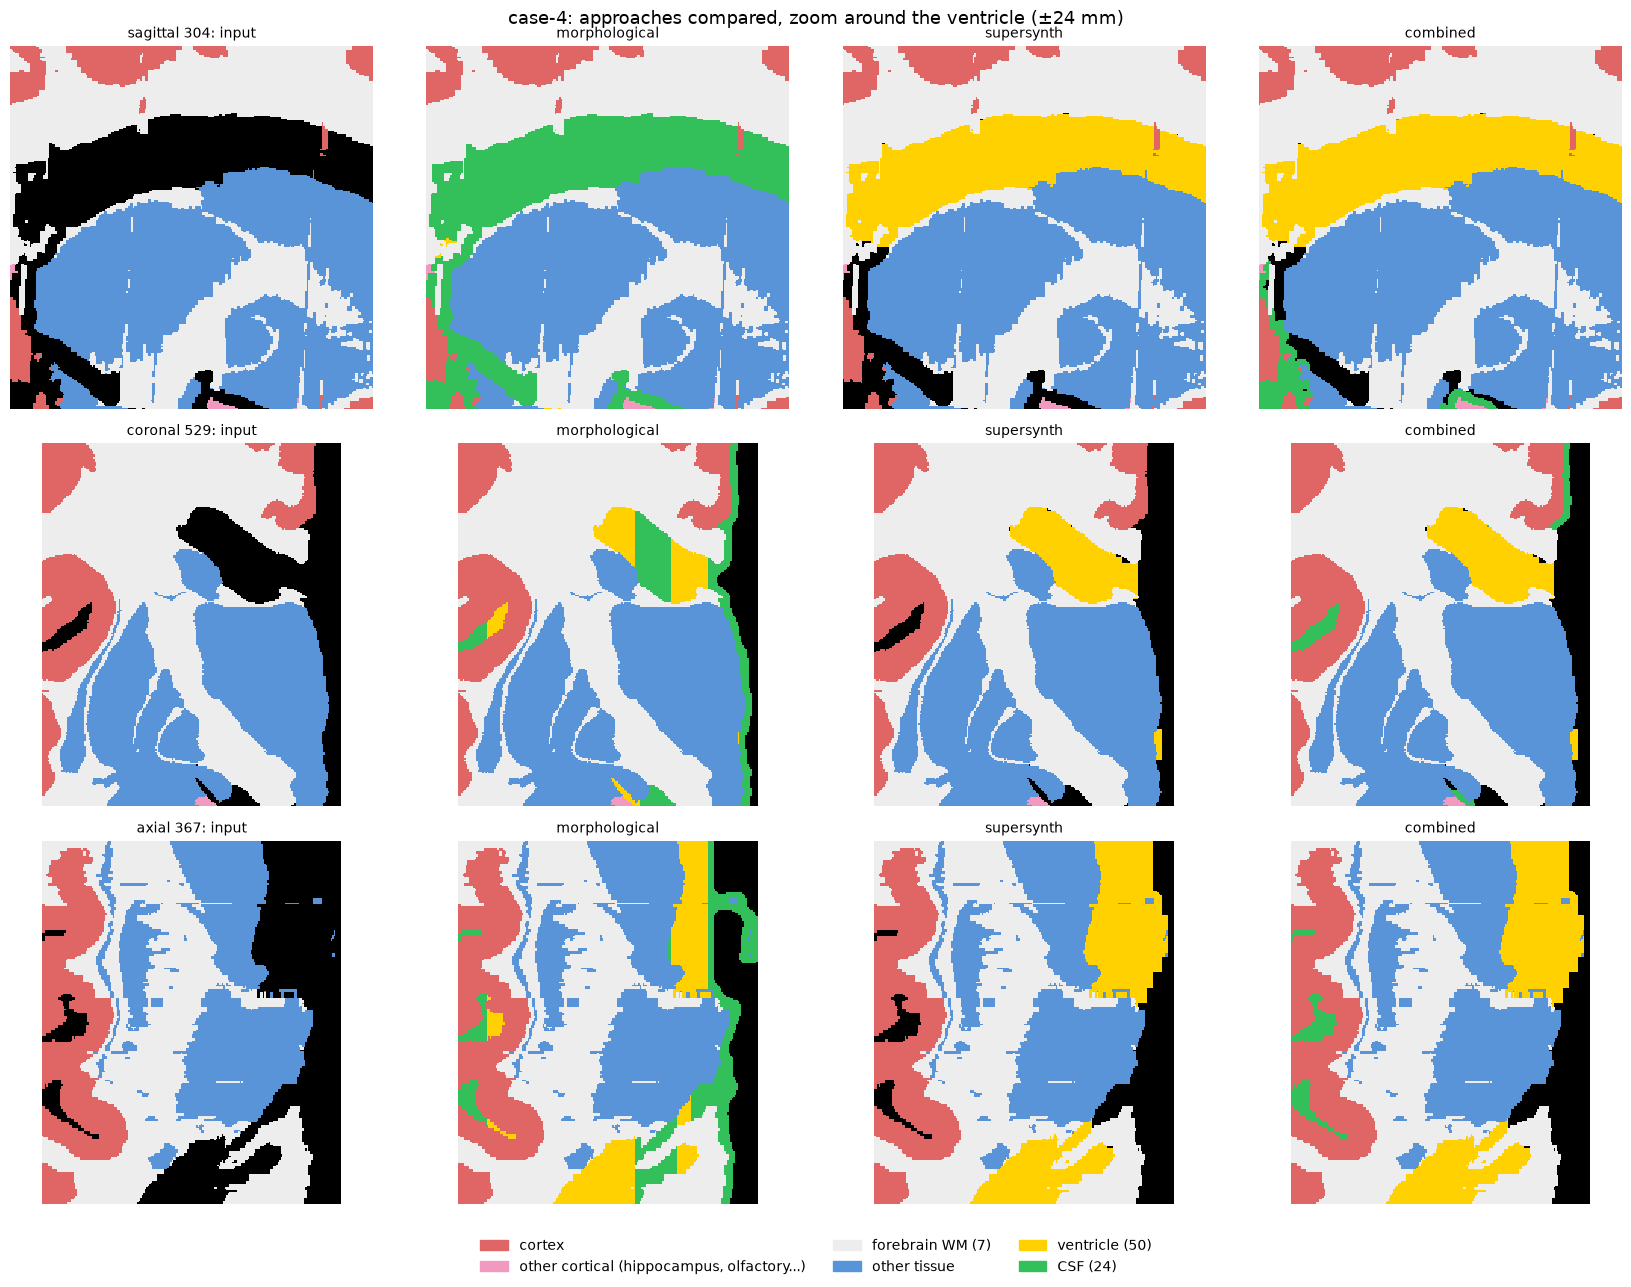

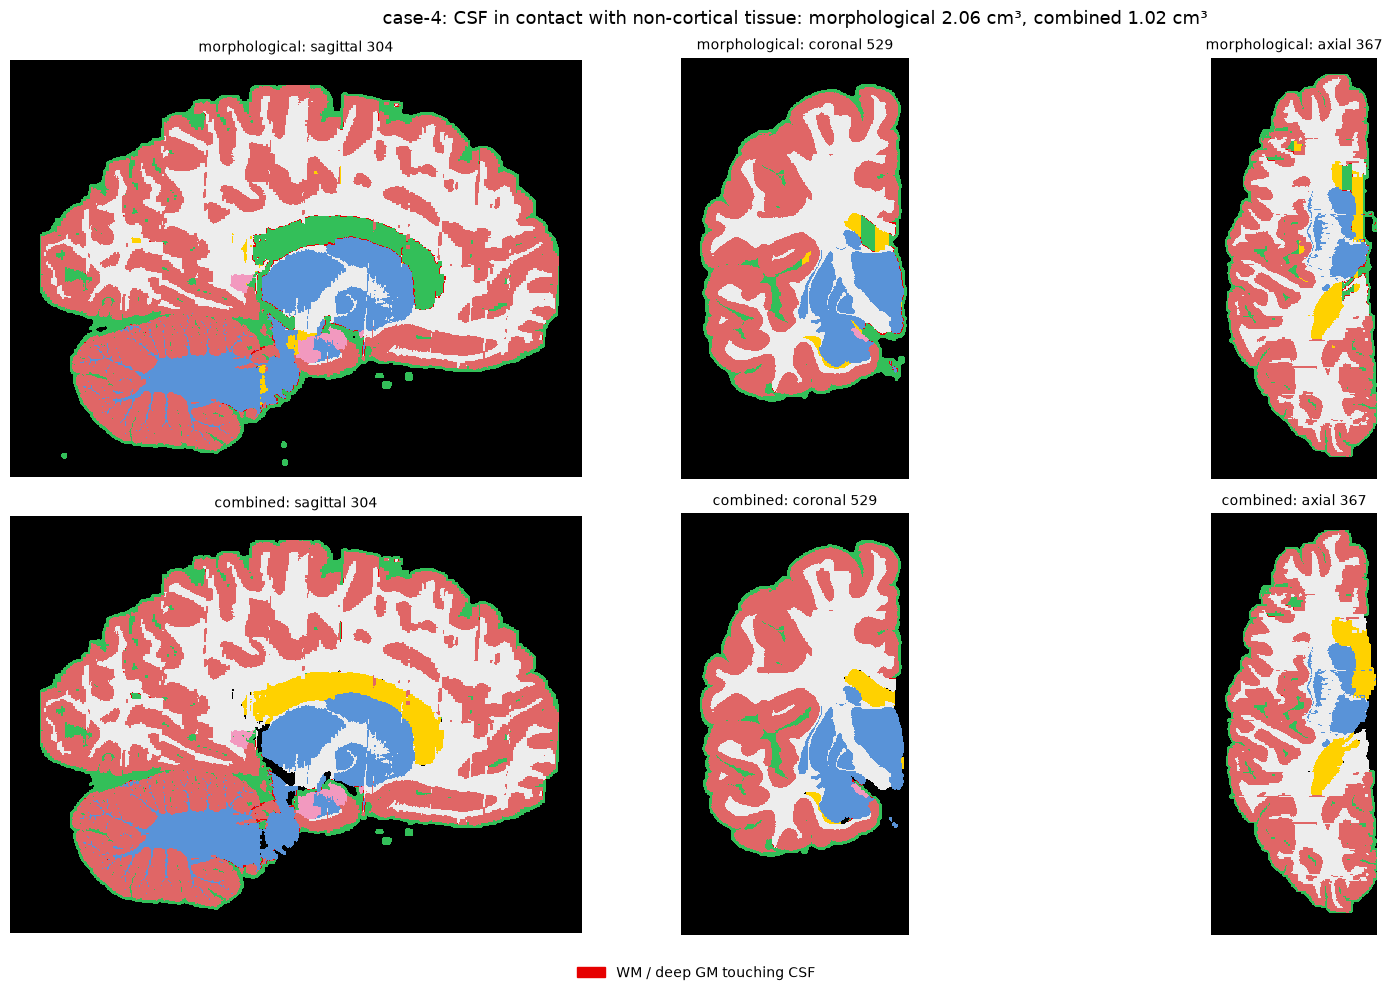

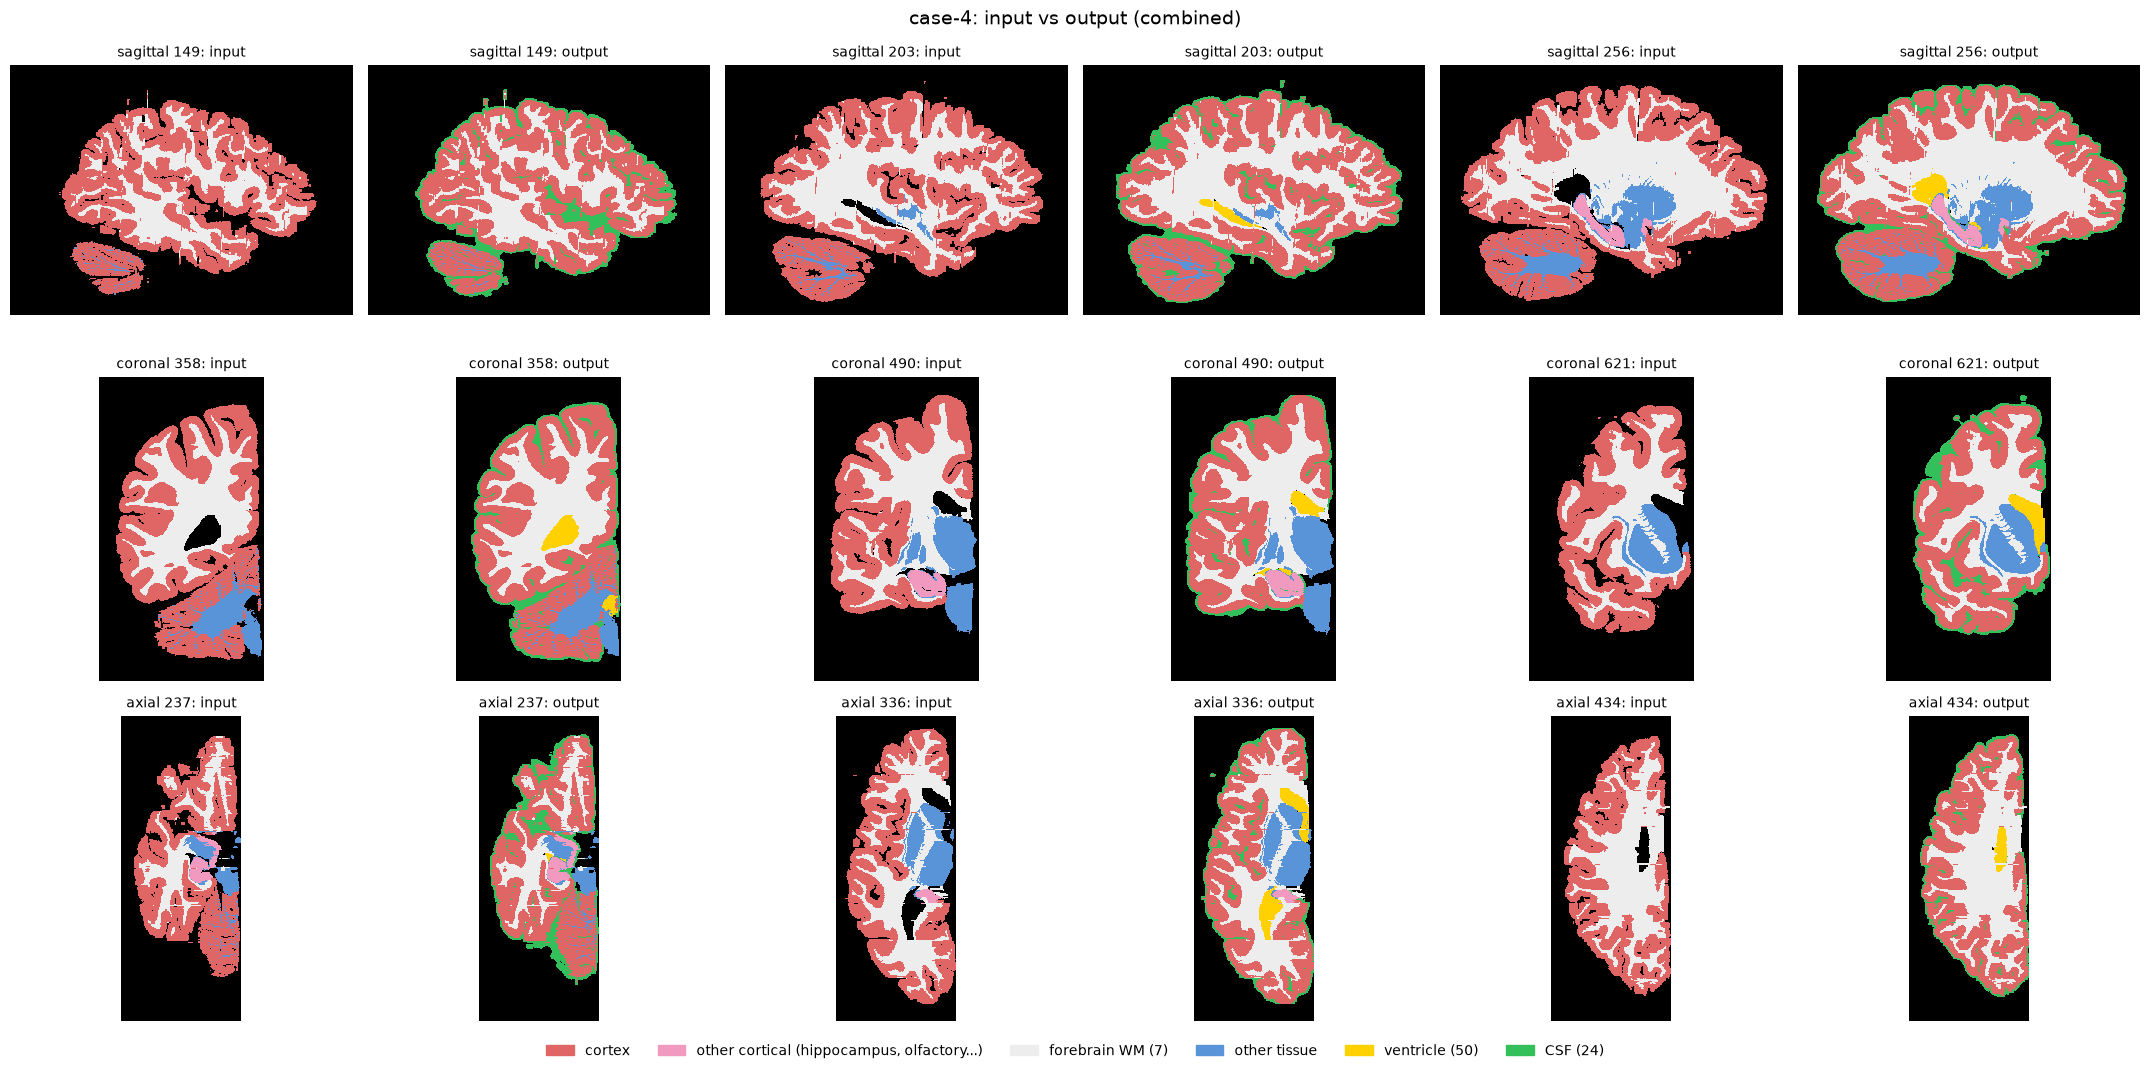

In [7]:
case = "case-4"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
plot_process(case, d)
plot_closing(case, d)
plot_compare(case, d)
plot_contact(case, d)
plot_result(case, d)
del d

### case-5

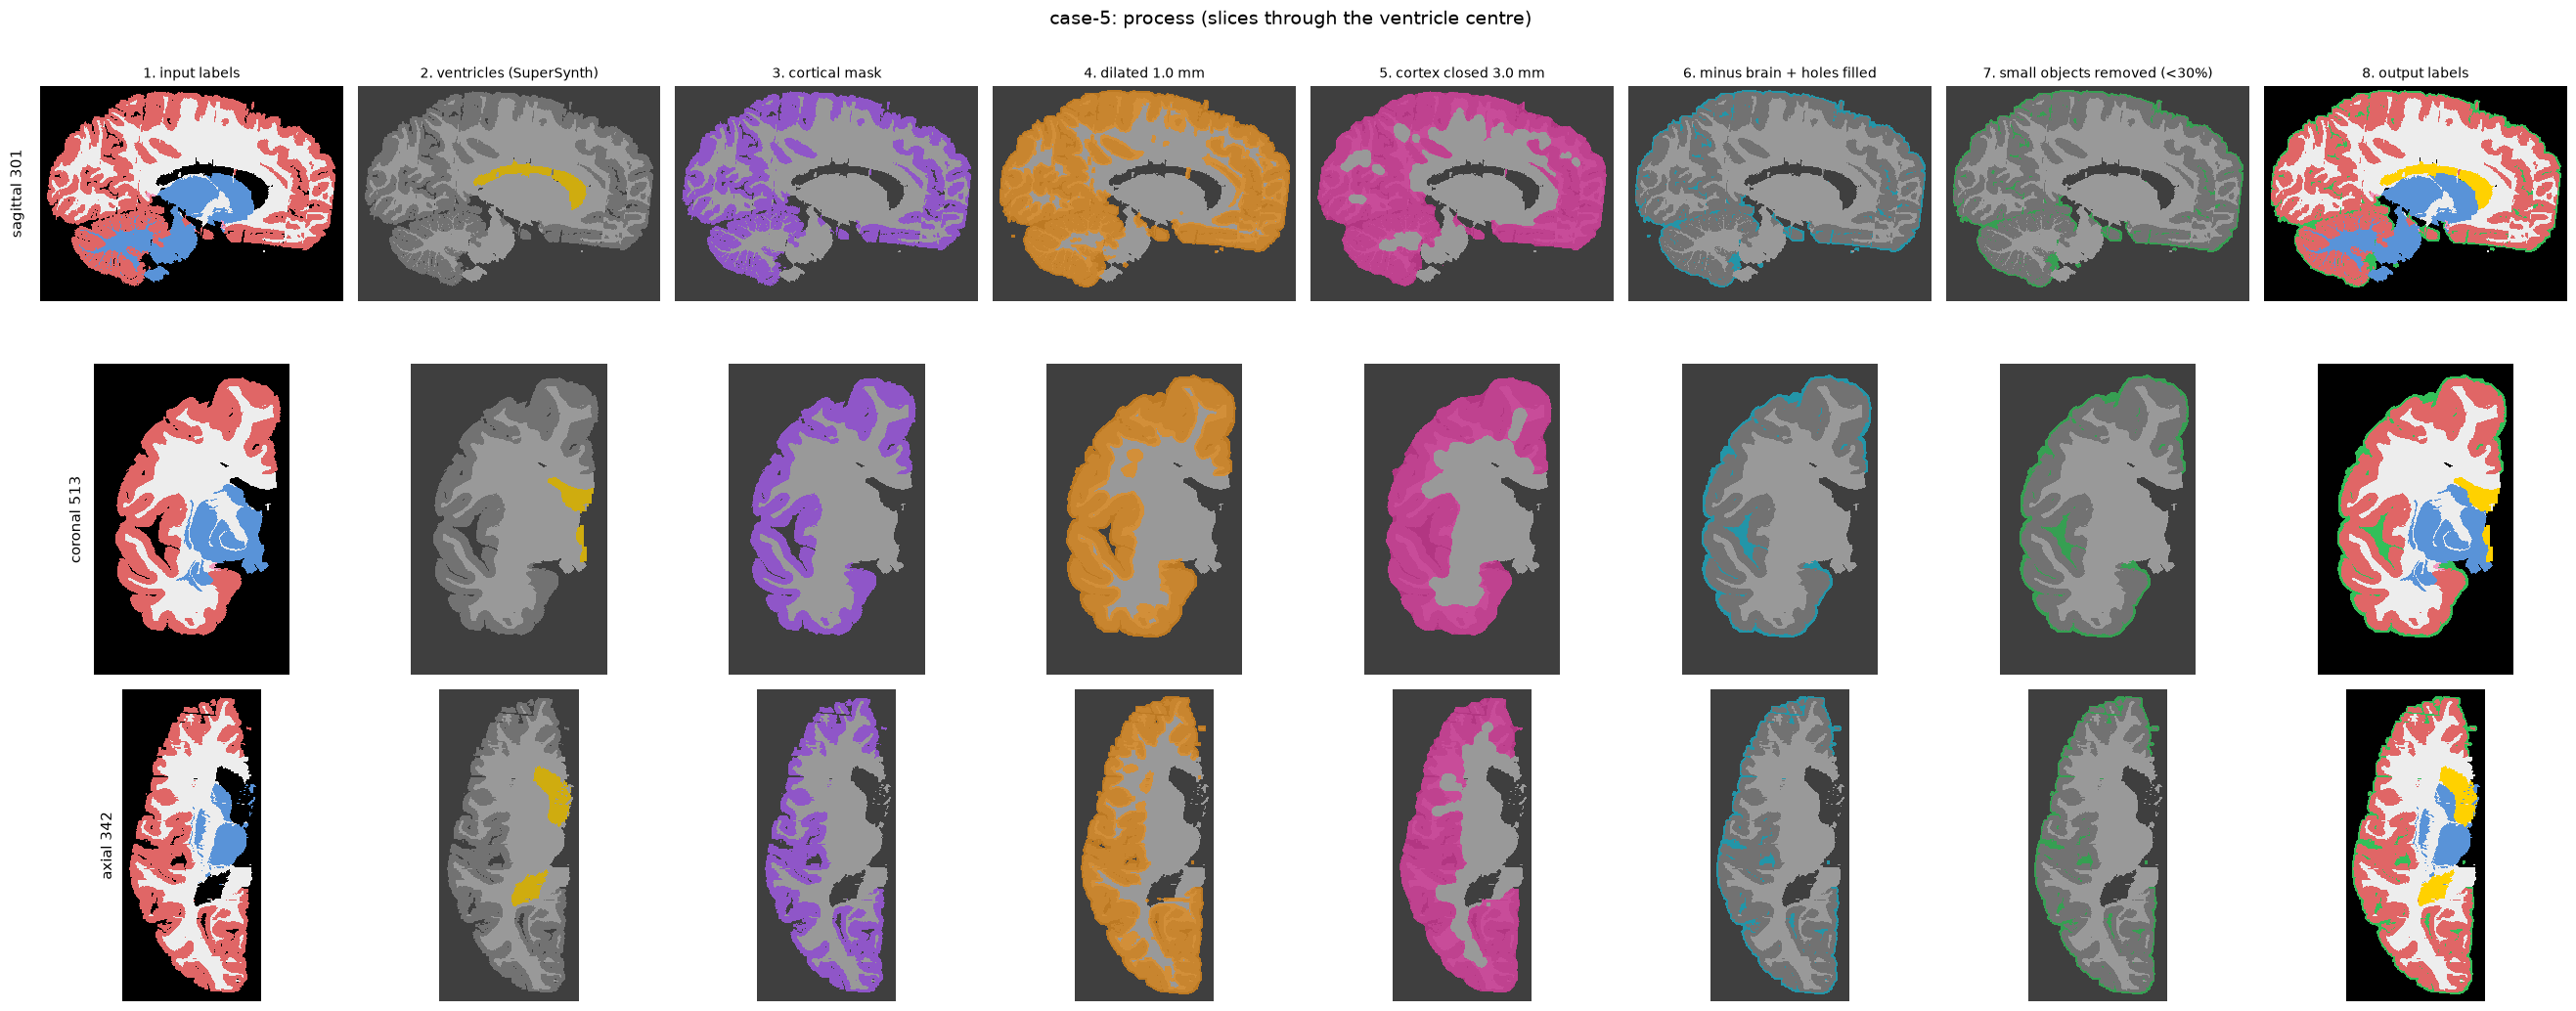

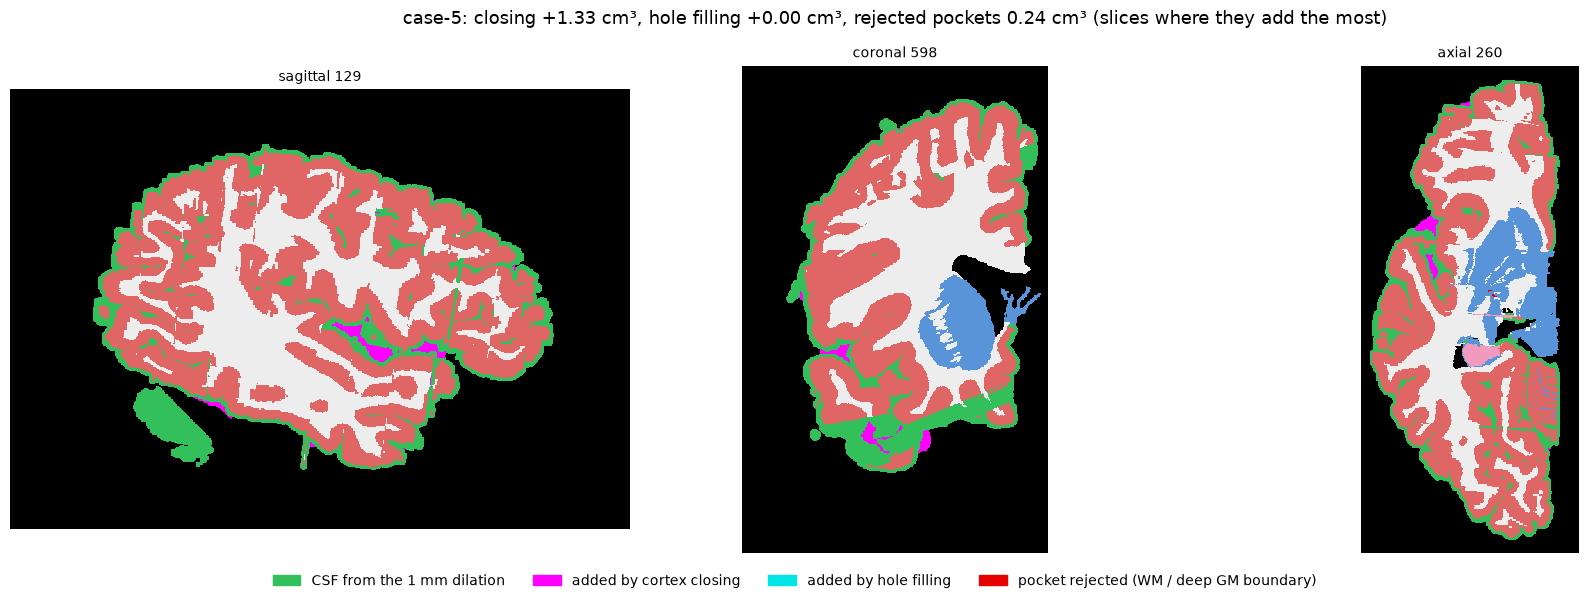

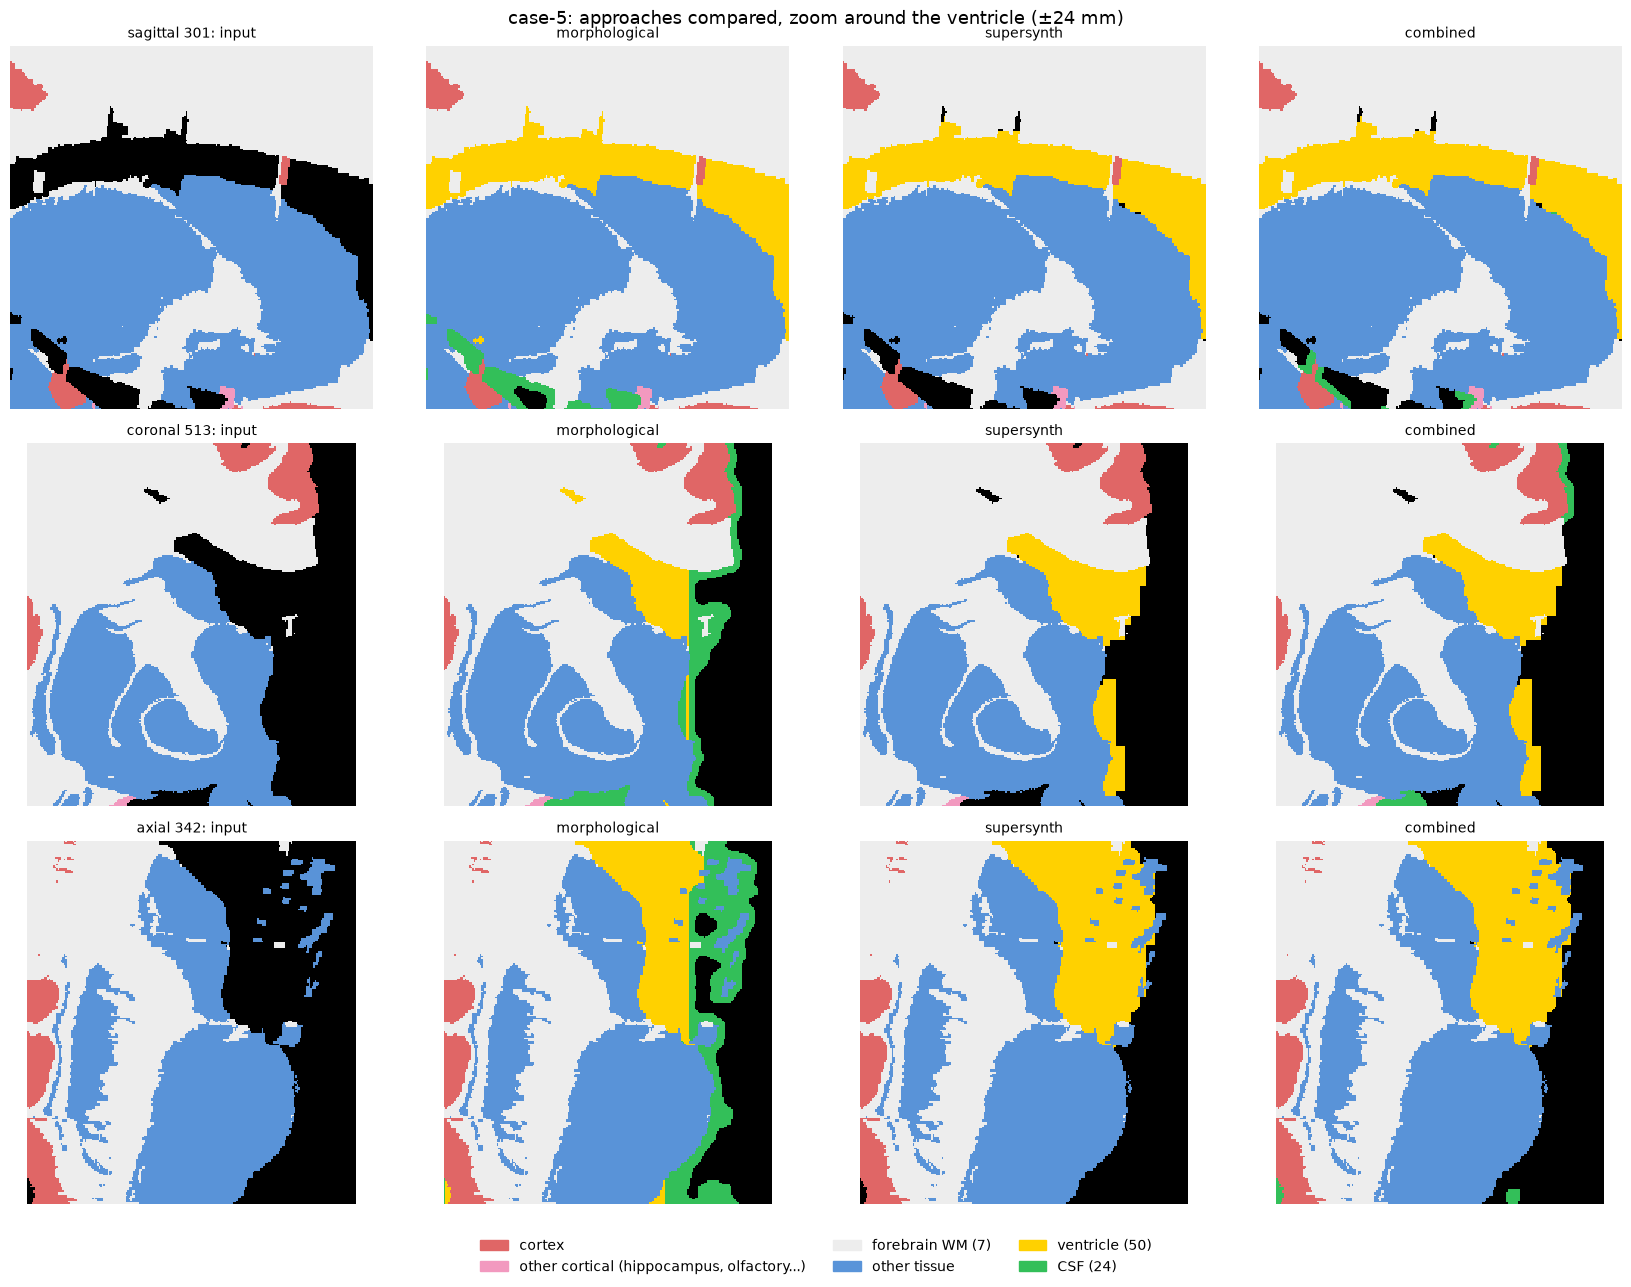

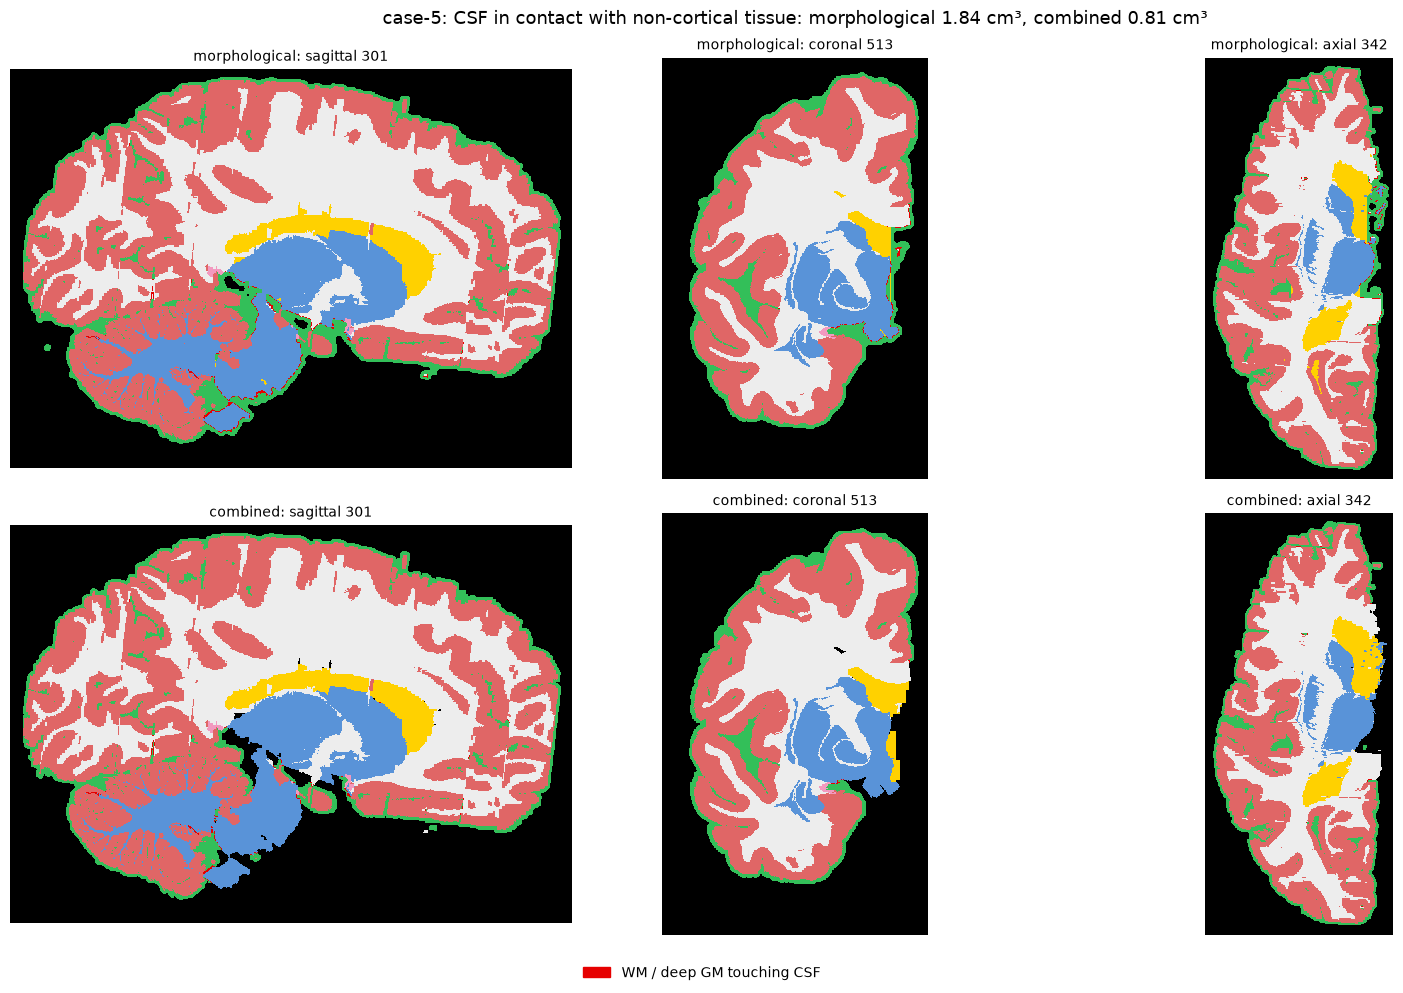

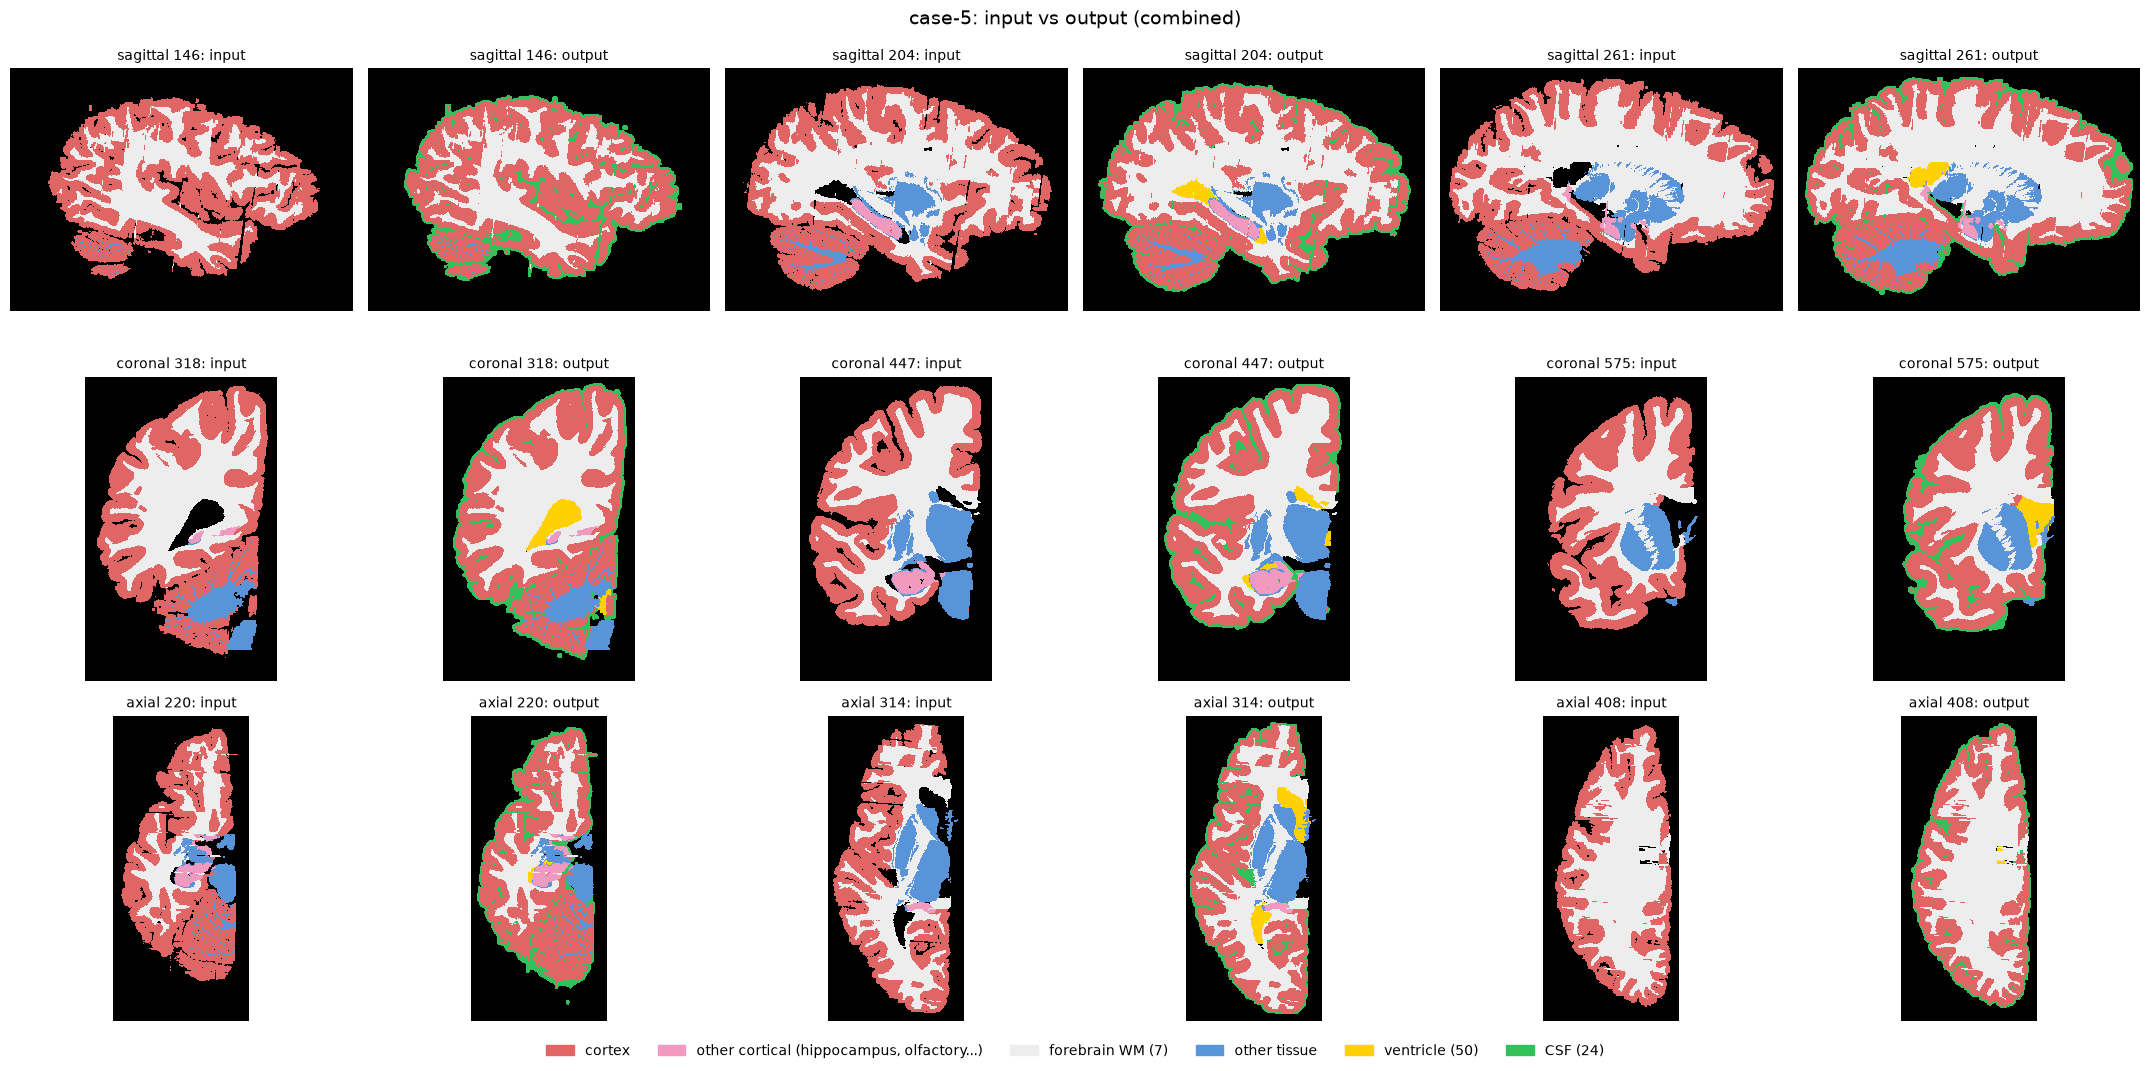

In [8]:
case = "case-5"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
plot_process(case, d)
plot_closing(case, d)
plot_compare(case, d)
plot_contact(case, d)
plot_result(case, d)
del d

## Summary: the three approaches (cm³ per hemisphere)

,ventricle morphological,CSF morphological,WM/deepGM touching CSF morphological,ventricle supersynth,CSF supersynth,WM/deepGM touching CSF supersynth,ventricle combined,CSF combined,WM/deepGM touching CSF combined
case,,,,,,,,,
case-1,9.19,75.19,1.38,9.19,0.0,0.0,9.19,66.96,0.56
case-2,14.54,64.00,1.36,14.68,0.0,0.0,14.68,54.68,0.49
case-3,14.67,80.04,1.66,16.12,0.0,0.0,16.12,70.42,0.68
case-4,10.89,94.09,2.06,14.87,0.0,0.0,14.87,83.15,1.02
case-5,11.50,84.21,1.84,11.87,0.0,0.0,11.87,74.05,0.81


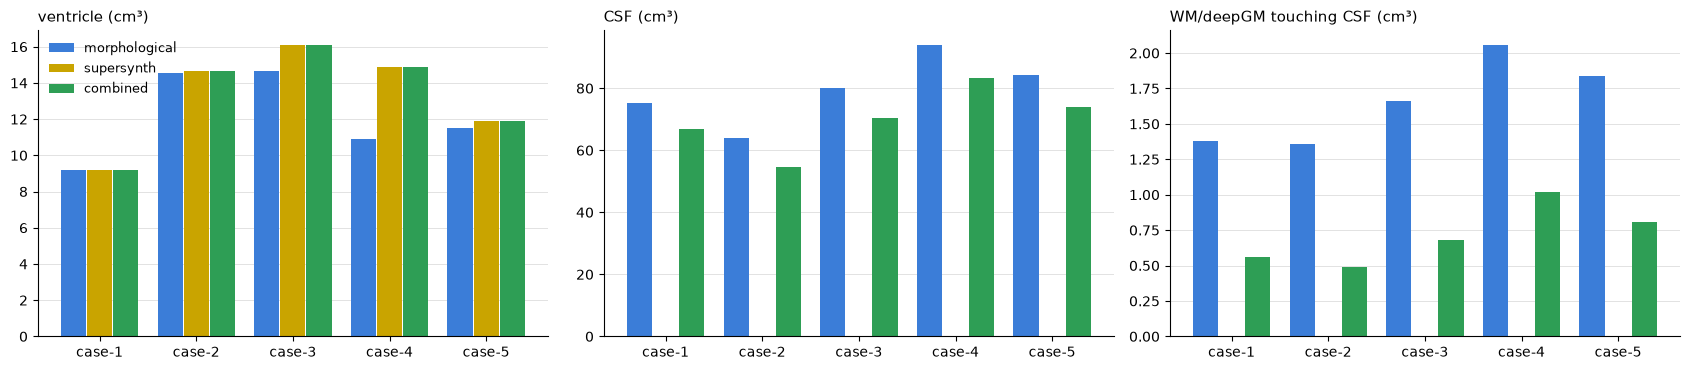

In [9]:
df = pd.DataFrame([ROWS[c] for c in CASES]).set_index("case").astype(float).round(2)
display(df)

names = [a.replace("_approach", "") for a in APPROACHES]
colors = ["#3b7dd8", "#c9a400", "#2e9e55"]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, metric in zip(axes, ["ventricle", "CSF", "WM/deepGM touching CSF"]):
    x = np.arange(len(df)); w = 0.26
    for j, (n, c) in enumerate(zip(names, colors)):
        if metric == "WM/deepGM touching CSF" and n == "supersynth":
            continue  # no CSF in the supersynth approach
        ax.bar(x + (j - 1) * (w + 0.01), df[f"{metric} {n}"], w, color=c, label=n)
    ax.set_xticks(x, df.index)
    ax.set_title(f"{metric} (cm³)", loc="left", fontsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", color="#ddd", linewidth=0.6); ax.set_axisbelow(True)
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()